In [2]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

from tqdm.auto import tqdm

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================================
# CELL 2 & 3 — COLAB KAGGLE SETUP & DATA DOWNLOADING (TOKEN INPUT)
# ============================================================

import os
import getpass
from pathlib import Path

# 1. Prompt for Kaggle credentials

# 4. Set DATASET_DIR to the extracted audio_and_txt_files directory
DATASET_DIR = "/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files"

SEED = 42
import random
import numpy as np

random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

# Audio settings
TARGET_SR = 4000

# Feature extraction settings
N_FFT = 1024
HOP_LENGTH = 256

# Number of classes
NUM_CLASSES = 4

CLASS_NAMES = [
    "Normal",
    "Crackle",
    "Wheeze",
    "Both"
]

LABEL_MAP = {
    (0, 0): "Normal",
    (1, 0): "Crackle",
    (0, 1): "Wheeze",
    (1, 1): "Both"
}

print("\nDataset downloaded and configuration loaded successfully!")


Dataset downloaded and configuration loaded successfully!


In [4]:
# ============================================================
# CELL 4 — FIND ALL WAV FILES
# ============================================================

wav_files = sorted(
    Path(DATASET_DIR).rglob("*.wav")
)

txt_files = sorted(
    Path(DATASET_DIR).rglob("*.txt")
)

print("Number of WAV files:", len(wav_files))
print("Number of TXT files:", len(txt_files))

print("\nFirst 5 WAV files:")
for f in wav_files[:5]:
    print(f)

Number of WAV files: 920
Number of TXT files: 920

First 5 WAV files:
/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files/101_1b1_Al_sc_Meditron.wav
/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files/101_1b1_Pr_sc_Meditron.wav
/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files/102_1b1_Ar_sc_Meditron.wav
/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files/103_2b2_Ar_mc_LittC2SE.wav
/kaggle/input/datasets/vbookshelf/respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files/104_1b1_Al_sc_Litt3200.wav


In [5]:
# ============================================================
# CELL 5 — READ RESPIRATORY CYCLE ANNOTATIONS
# ============================================================

def read_annotation(txt_path):

    rows = []

    with open(txt_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) < 4:
                continue

            start = float(parts[0])
            end = float(parts[1])

            crackle = int(parts[2])
            wheeze = int(parts[3])

            label = LABEL_MAP[(crackle, wheeze)]

            rows.append({
                "start": start,
                "end": end,
                "crackle": crackle,
                "wheeze": wheeze,
                "label": label
            })

    return rows


# Test on one file
example_txt = txt_files[0]

annotations = read_annotation(example_txt)

print("File:", example_txt.name)
print("Number of cycles:", len(annotations))

print("\nFirst 5 annotations:")
pd.DataFrame(annotations).head()

File: 101_1b1_Al_sc_Meditron.txt
Number of cycles: 12

First 5 annotations:


,start,end,crackle,wheeze,label
0,0.036,0.579,0,0,Normal
1,0.579,2.450,0,0,Normal
2,2.450,3.893,0,0,Normal
3,3.893,5.793,0,0,Normal
4,5.793,7.521,0,0,Normal


In [6]:
# ============================================================
# CELL 6 — BUILD RESPIRATORY-CYCLE METADATA
# ============================================================

records = []

for wav_path in tqdm(wav_files):

    txt_path = wav_path.with_suffix(".txt")

    if not txt_path.exists():
        continue

    patient_id = wav_path.stem.split("_")[0]

    annotations = read_annotation(txt_path)

    for cycle_id, ann in enumerate(annotations):

        records.append({
            "file": str(wav_path),
            "patient": patient_id,
            "cycle_id": cycle_id,
            "start": ann["start"],
            "end": ann["end"],
            "duration": ann["end"] - ann["start"],
            "crackle": ann["crackle"],
            "wheeze": ann["wheeze"],
            "label": ann["label"]
        })


metadata = pd.DataFrame(records)

print("Total respiratory cycles:", len(metadata))
print("Unique patients:", metadata["patient"].nunique())
print("Unique recordings:", metadata["file"].nunique())

metadata.head(40)

  0%|          | 0/920 [00:00<?, ?it/s]

Total respiratory cycles: 6898
Unique patients: 126
Unique recordings: 920


,file,patient,cycle_id,start,end,duration,crackle,wheeze,label
0,/kaggle/input/datasets/vbookshelf/respiratory-...,101,0,0.036,0.579,0.543,0,0,Normal
1,/kaggle/input/datasets/vbookshelf/respiratory-...,101,1,0.579,2.450,1.871,0,0,Normal
2,/kaggle/input/datasets/vbookshelf/respiratory-...,101,2,2.450,3.893,1.443,0,0,Normal
3,/kaggle/input/datasets/vbookshelf/respiratory-...,101,3,3.893,5.793,1.900,0,0,Normal
4,/kaggle/input/datasets/vbookshelf/respiratory-...,101,4,5.793,7.521,1.728,0,0,Normal
5,/kaggle/input/datasets/vbookshelf/respiratory-...,101,5,7.521,9.279,1.758,0,0,Normal
6,/kaggle/input/datasets/vbookshelf/respiratory-...,101,6,9.279,11.150,1.871,0,0,Normal
7,/kaggle/input/datasets/vbookshelf/respiratory-...,101,7,11.150,13.036,1.886,0,0,Normal
8,/kaggle/input/datasets/vbookshelf/respiratory-...,101,8,13.036,14.721,1.685,0,0,Normal
9,/kaggle/input/datasets/vbookshelf/respiratory-...,101,9,14.721,16.707,1.986,0,0,Normal


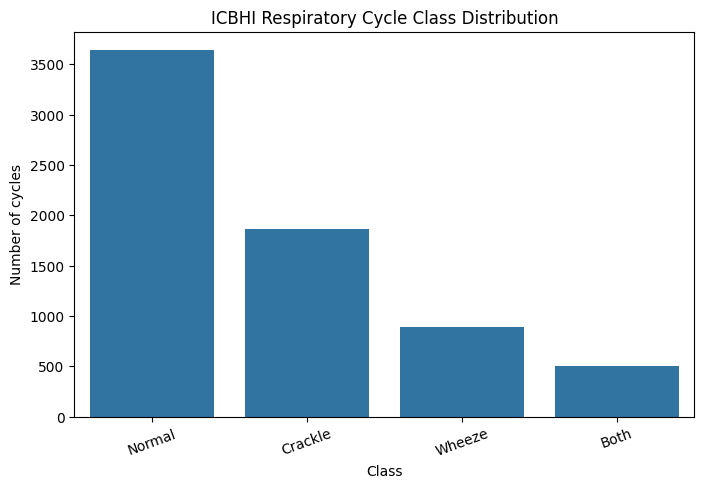

label
Normal     3642
Crackle    1864
Wheeze      886
Both        506
Name: count, dtype: int64


In [7]:
# ============================================================
# CELL 7 — CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=metadata,
    x="label",
    order=CLASS_NAMES
)

plt.title("ICBHI Respiratory Cycle Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of cycles")
plt.xticks(rotation=20)

plt.show()

print(
    metadata["label"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

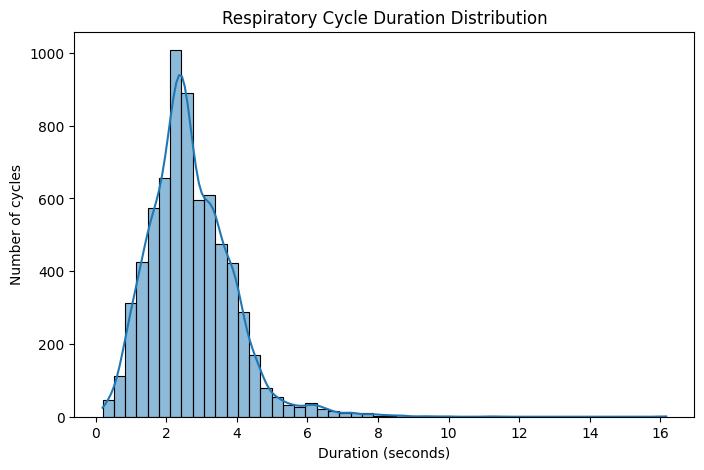

count    6898.000000
mean        2.700509
std         1.172534
min         0.200000
25%         1.932000
50%         2.537000
75%         3.369000
max        16.163000
Name: duration, dtype: float64


In [8]:
# ============================================================
# CELL 9 — RESPIRATORY CYCLE DURATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    metadata["duration"],
    bins=50,
    kde=True
)

plt.title("Respiratory Cycle Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of cycles")

plt.show()

print(metadata["duration"].describe())

In [9]:
# ============================================================
# CELL 10 — LOAD EXAMPLE CYCLES
# ============================================================

def load_cycle(row, target_sr=TARGET_SR):

    audio, sr = librosa.load(
        row["file"],
        sr=target_sr,
        mono=True
    )

    start_sample = int(row["start"] * target_sr)
    end_sample = int(row["end"] * target_sr)

    cycle = audio[start_sample:end_sample]

    return cycle, target_sr


examples = {}

for label in CLASS_NAMES:

    row = metadata[
        metadata["label"] == label
    ].iloc[0]

    cycle, sr = load_cycle(row)

    examples[label] = cycle

print("Examples loaded.")

Examples loaded.


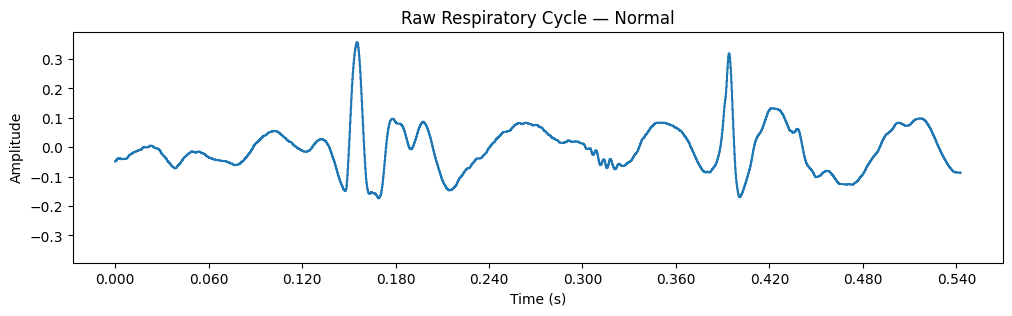

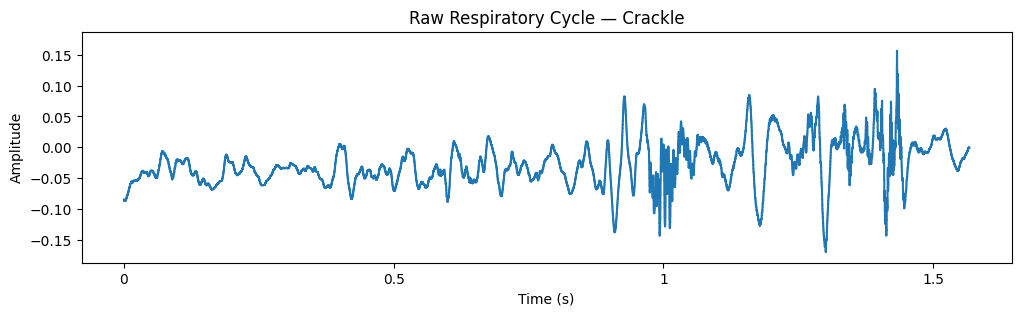

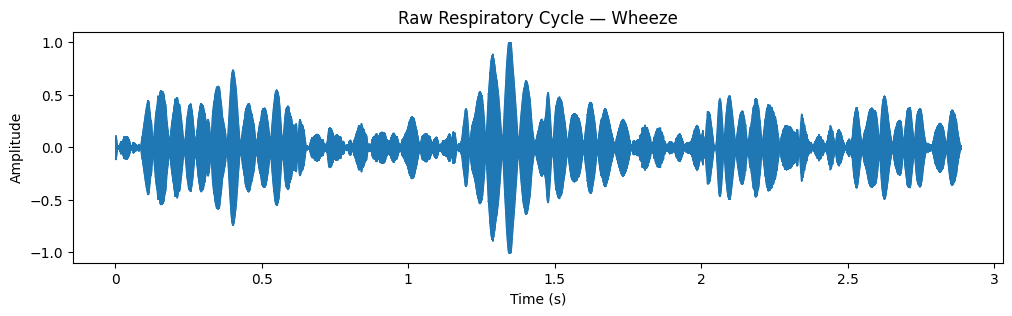

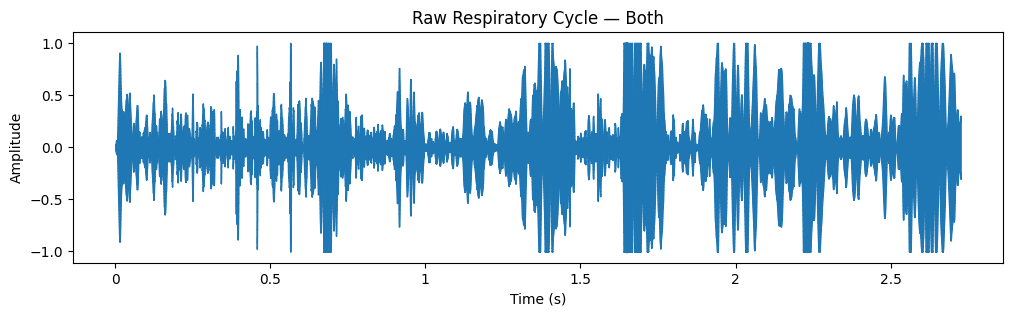

In [10]:
# ============================================================
# CELL 11 — RAW WAVEFORM VISUALIZATION
# ============================================================

for label in CLASS_NAMES:

    audio = examples[label]

    plt.figure(figsize=(12, 3))

    librosa.display.waveshow(
        audio,
        sr=TARGET_SR
    )

    plt.title(f"Raw Respiratory Cycle — {label}")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")

    plt.show()

In [11]:
# ============================================================
# CELL — IMPORT LIBRARIES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import librosa
import librosa.display

from scipy.signal import butter, sosfiltfilt

import pywt

from pathlib import Path
from tqdm.auto import tqdm

print("Libraries imported successfully.")

Libraries imported successfully.


In [12]:
# ============================================================
# CELL — AUDIO / FILTER PARAMETERS
# ============================================================

TARGET_SR = 4000

# ------------------------------------------------------------
# 3rd-order Butterworth band-pass
# ------------------------------------------------------------

FILTER_ORDER = 3

LOWCUT = 100       # Hz
HIGHCUT = 1900     # Hz

# ------------------------------------------------------------
# STFT
# ------------------------------------------------------------

N_FFT = 1024
HOP_LENGTH = 256

# ------------------------------------------------------------
# Log-Mel
# ------------------------------------------------------------

N_MELS = 128
FMIN = 100
FMAX = 1900

print("Target sampling rate:", TARGET_SR)
print("Band-pass:", LOWCUT, "to", HIGHCUT, "Hz")
print("Filter order:", FILTER_ORDER)

Target sampling rate: 4000
Band-pass: 100 to 1900 Hz
Filter order: 3


In [13]:
# ============================================================
# CELL — 3rd ORDER BUTTERWORTH BAND-PASS FILTER
# ============================================================

def butter_bandpass_filter(
    audio,
    lowcut=LOWCUT,
    highcut=HIGHCUT,
    fs=TARGET_SR,
    order=FILTER_ORDER
):

    # --------------------------------------------------------
    # Design Butterworth band-pass filter
    # --------------------------------------------------------

    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    # --------------------------------------------------------
    # Zero-phase filtering
    # --------------------------------------------------------

    filtered_audio = sosfiltfilt(
        sos,
        audio
    )

    return filtered_audio.astype(
        np.float32
    )

In [14]:
# ============================================================
# CELL — LOAD + RESAMPLE + BANDPASS
# ============================================================

def load_and_preprocess_audio(
    file_path,
    target_sr=TARGET_SR
):

    # --------------------------------------------------------
    # Load mono audio
    # --------------------------------------------------------

    audio, original_sr = librosa.load(
        file_path,
        sr=None,
        mono=True
    )

    # --------------------------------------------------------
    # Resample
    # --------------------------------------------------------

    if original_sr != target_sr:

        audio = librosa.resample(
            audio,
            orig_sr=original_sr,
            target_sr=target_sr
        )

    # --------------------------------------------------------
    # Normalize amplitude
    # --------------------------------------------------------

    max_amplitude = np.max(
        np.abs(audio)
    )

    if max_amplitude > 0:

        audio = (
            audio / max_amplitude
        )

    # --------------------------------------------------------
    # 3rd-order Butterworth band-pass
    # --------------------------------------------------------

    audio = butter_bandpass_filter(
        audio
    )

    return audio.astype(
        np.float32
    ), target_sr

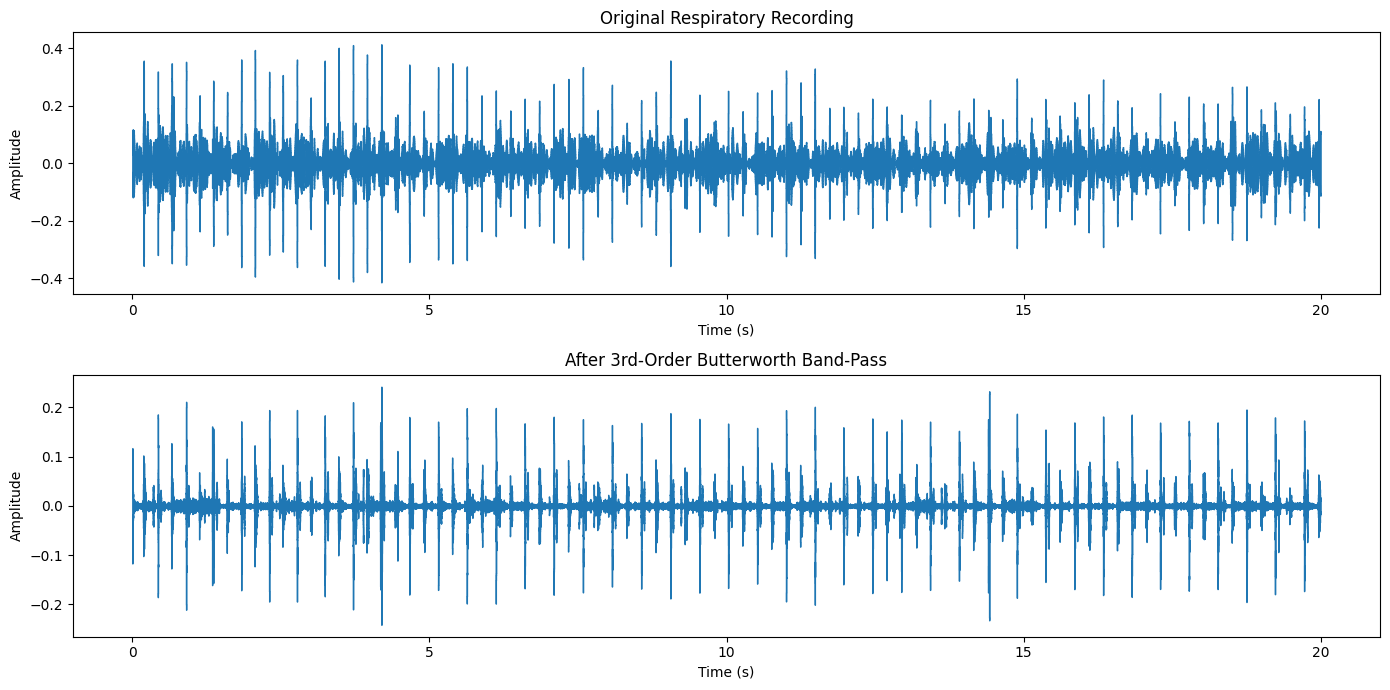

In [15]:
# ============================================================
# CELL — RAW VS FILTERED WAVEFORM
# ============================================================

# Select one WAV file
example_file = str(wav_files[0])

# Load original
raw_audio, original_sr = librosa.load(
    example_file,
    sr=None,
    mono=True
)

# Load processed
filtered_audio, processed_sr = load_and_preprocess_audio(
    example_file
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(14, 7))

plt.subplot(2, 1, 1)

librosa.display.waveshow(
    raw_audio,
    sr=original_sr
)

plt.title(
    "Original Respiratory Recording"
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")


plt.subplot(2, 1, 2)

librosa.display.waveshow(
    filtered_audio,
    sr=processed_sr
)

plt.title(
    "After 3rd-Order Butterworth Band-Pass"
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# CELL — EXTRACT PREPROCESSED RESPIRATORY CYCLE
# ============================================================

def load_filtered_cycle(row):

    audio, sr = load_and_preprocess_audio(
        row["file"]
    )

    start_sample = int(
        row["start"] * sr
    )

    end_sample = int(
        row["end"] * sr
    )

    cycle = audio[
        start_sample:end_sample
    ]

    return cycle, sr

In [17]:
# ============================================================
# CELL 12 — PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

groups = metadata["patient"].values

# First: 80% train+validation, 20% test
gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_val_idx, test_idx = next(
    gss1.split(metadata, groups=groups)
)

train_val_df = metadata.iloc[train_val_idx].reset_index(drop=True)
test_df = metadata.iloc[test_idx].reset_index(drop=True)


# Second: split train/validation
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

groups_train_val = train_val_df["patient"].values

train_idx, val_idx = next(
    gss2.split(
        train_val_df,
        groups=groups_train_val
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)


print("TRAIN")
print("Cycles:", len(train_df))
print("Patients:", train_df["patient"].nunique())

print("\nVALIDATION")
print("Cycles:", len(val_df))
print("Patients:", val_df["patient"].nunique())

print("\nTEST")
print("Cycles:", len(test_df))
print("Patients:", test_df["patient"].nunique())

TRAIN
Cycles: 3800
Patients: 80

VALIDATION
Cycles: 1395
Patients: 20

TEST
Cycles: 1703
Patients: 26


In [18]:
# ============================================================
# CELL 13 — VERIFY PATIENT SEPARATION
# ============================================================

train_patients = set(train_df["patient"])
val_patients = set(val_df["patient"])
test_patients = set(test_df["patient"])

print("Train ∩ Validation:", train_patients & val_patients)
print("Train ∩ Test:", train_patients & test_patients)
print("Validation ∩ Test:", val_patients & test_patients)

assert len(train_patients & val_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(val_patients & test_patients) == 0

print("\n✓ No patient leakage.")

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()

✓ No patient leakage.


In [19]:
# ============================================================
# CELL — STFT
# ============================================================

def extract_stft(audio):

    stft = librosa.stft(
        y=audio,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        window="hann",
        center=True
    )

    magnitude = np.abs(
        stft
    )

    # Convert amplitude to dB
    stft_db = librosa.amplitude_to_db(
        magnitude,
        ref=np.max
    )

    return stft_db

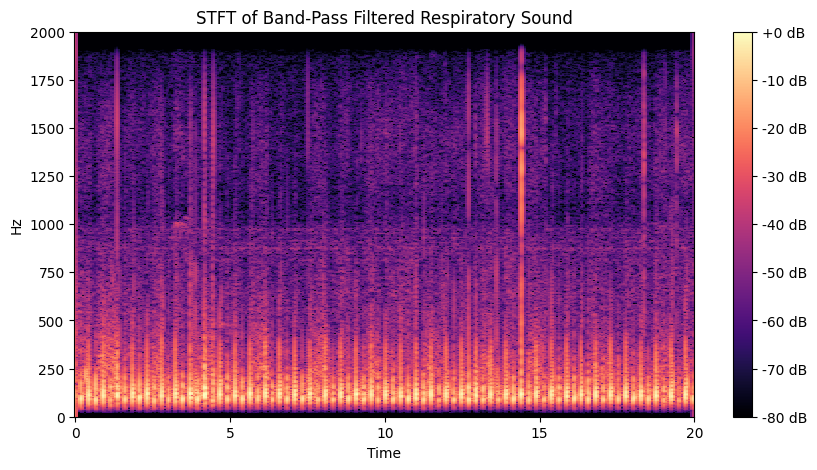

In [20]:
# ============================================================
# CELL — STFT VISUALIZATION
# ============================================================

stft_feature = extract_stft(
    filtered_audio
)

plt.figure(figsize=(10, 5))

librosa.display.specshow(
    stft_feature,
    sr=TARGET_SR,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.ylim(0, 2000)

plt.title(
    "STFT of Band-Pass Filtered Respiratory Sound"
)

plt.show()

In [21]:
# ============================================================
# CELL — CONTINUOUS WAVELET TRANSFORM (CWT)
# ============================================================

def extract_cwt(audio):

    # --------------------------------------------------------
    # Wavelet scales
    # --------------------------------------------------------

    scales = np.arange(
        1,
        128
    )

    # --------------------------------------------------------
    # Continuous Wavelet Transform
    # --------------------------------------------------------

    coefficients, frequencies = pywt.cwt(
        audio,
        scales,
        "morl",
        sampling_period=1 / TARGET_SR
    )

    # --------------------------------------------------------
    # Magnitude
    # --------------------------------------------------------

    magnitude = np.abs(
        coefficients
    )

    # Log compression
    magnitude = np.log1p(
        magnitude
    )

    return magnitude, frequencies

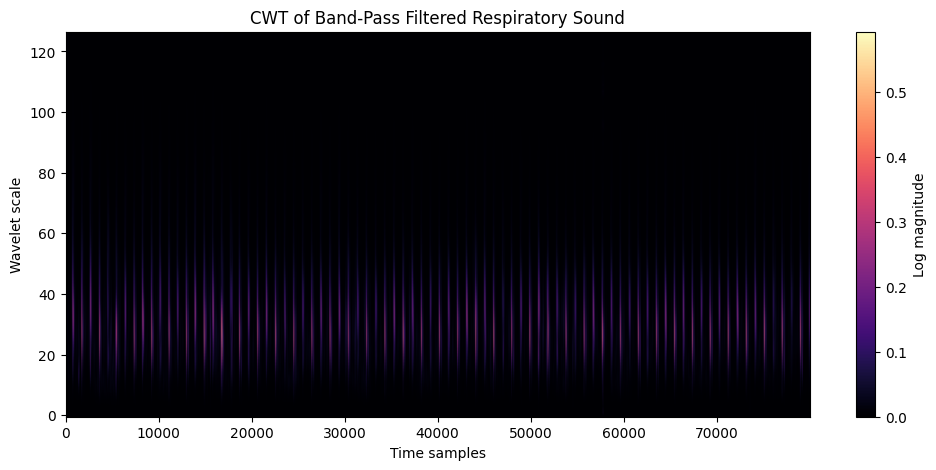

In [22]:
# ============================================================
# CELL — CWT VISUALIZATION
# ============================================================

cwt_feature, cwt_frequencies = extract_cwt(
    filtered_audio
)

plt.figure(figsize=(12, 5))

plt.imshow(
    cwt_feature,
    aspect="auto",
    origin="lower",
    cmap="magma"
)

plt.colorbar(
    label="Log magnitude"
)

plt.title(
    "CWT of Band-Pass Filtered Respiratory Sound"
)

plt.xlabel("Time samples")
plt.ylabel("Wavelet scale")

plt.show()

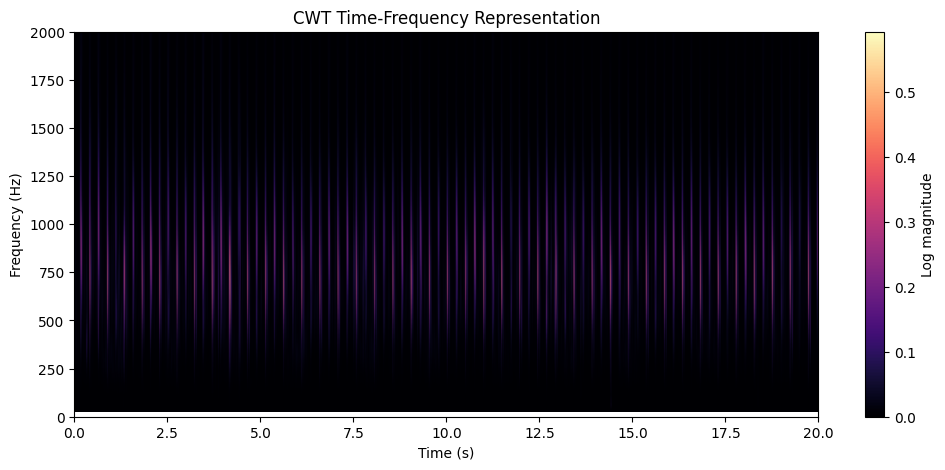

In [23]:
# ============================================================
# CELL — CWT WITH FREQUENCY AXIS
# ============================================================

plt.figure(figsize=(12, 5))

extent = [
    0,
    len(filtered_audio) / TARGET_SR,
    cwt_frequencies[-1],
    cwt_frequencies[0]
]

plt.imshow(
    cwt_feature,
    aspect="auto",
    extent=extent,
    origin="lower",
    cmap="magma"
)

plt.colorbar(
    label="Log magnitude"
)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, 2000)

plt.title(
    "CWT Time-Frequency Representation"
)

plt.show()

In [24]:
# ============================================================
# CELL — LOG-MEL SPECTROGRAM
# ============================================================

def extract_logmel(audio):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return log_mel

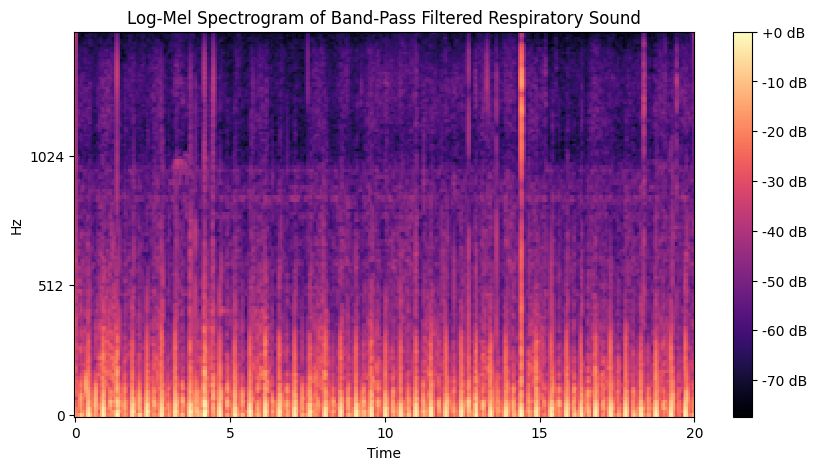

In [25]:
# ============================================================
# CELL — LOG-MEL VISUALIZATION
# ============================================================

logmel_feature = extract_logmel(
    filtered_audio
)

plt.figure(figsize=(10, 5))

librosa.display.specshow(
    logmel_feature,
    sr=TARGET_SR,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(
    format="%+2.0f dB"
)

plt.title(
    "Log-Mel Spectrogram of Band-Pass Filtered Respiratory Sound"
)

plt.show()

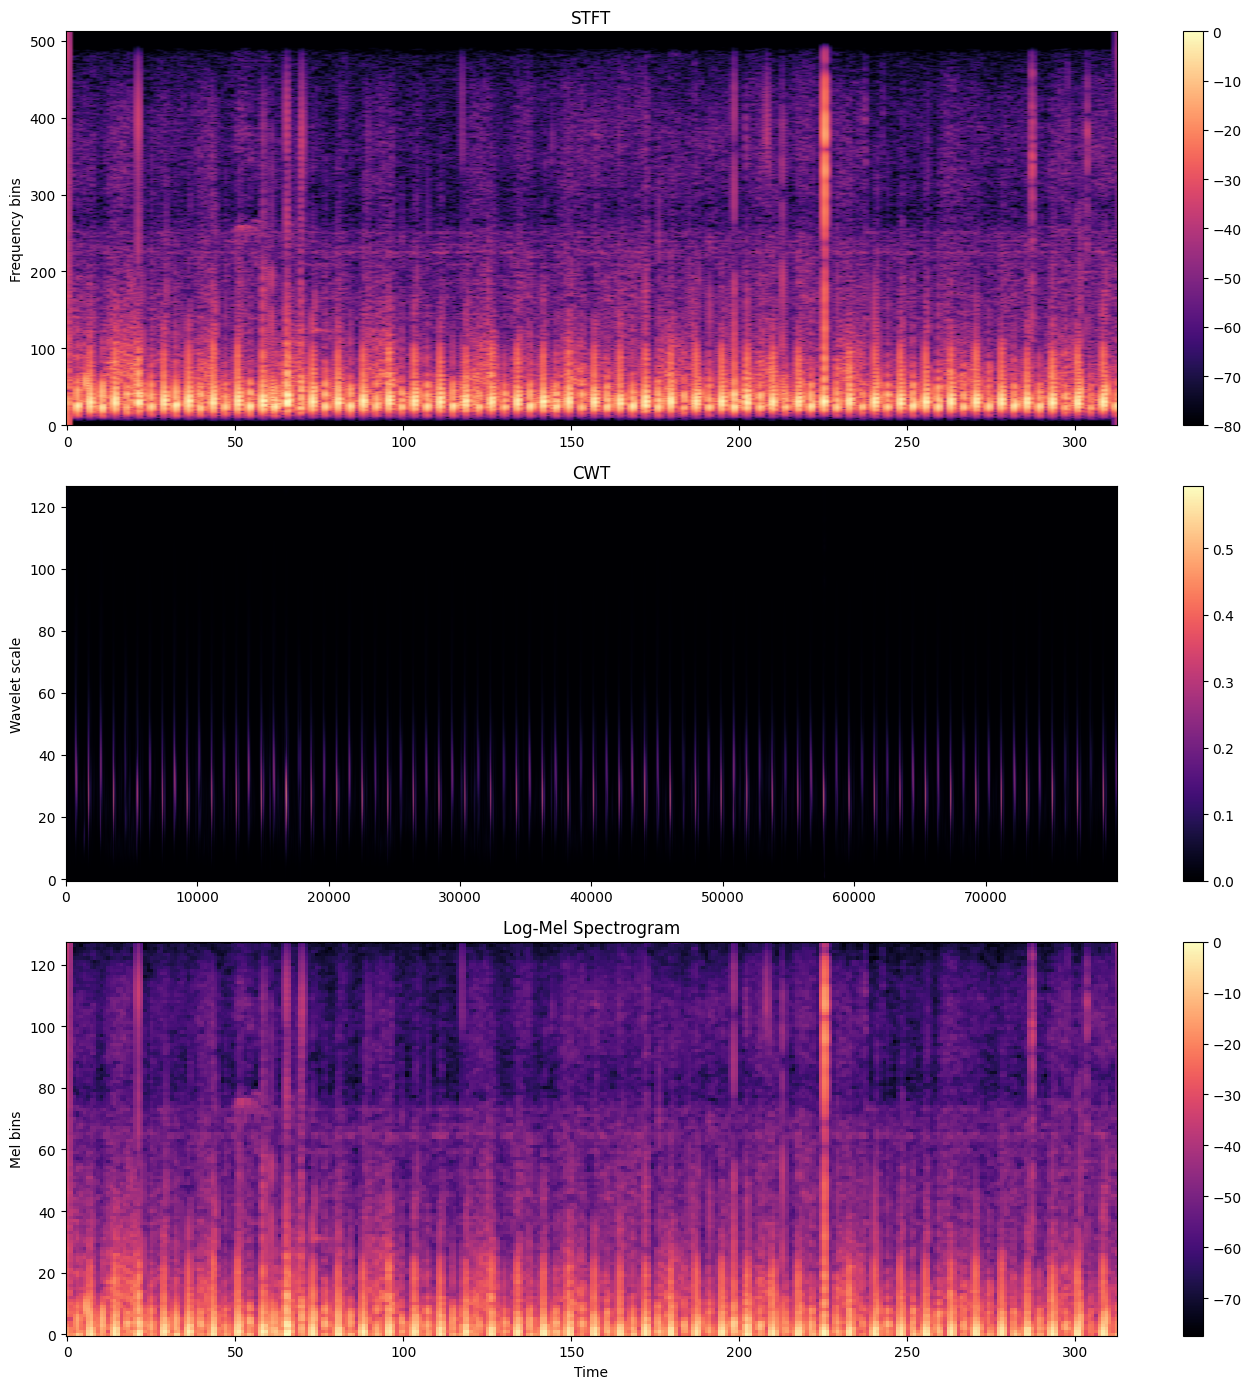

In [26]:
# ============================================================
# CELL — STFT vs CWT vs LOG-MEL
# ============================================================

stft_feature = extract_stft(
    filtered_audio
)

cwt_feature, cwt_freq = extract_cwt(
    filtered_audio
)

logmel_feature = extract_logmel(
    filtered_audio
)


fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 14)
)


# ------------------------------------------------------------
# STFT
# ------------------------------------------------------------

im1 = axes[0].imshow(
    stft_feature,
    aspect="auto",
    origin="lower",
    cmap="magma"
)

axes[0].set_title("STFT")
axes[0].set_ylabel("Frequency bins")

fig.colorbar(
    im1,
    ax=axes[0]
)


# ------------------------------------------------------------
# CWT
# ------------------------------------------------------------

im2 = axes[1].imshow(
    cwt_feature,
    aspect="auto",
    origin="lower",
    cmap="magma"
)

axes[1].set_title("CWT")
axes[1].set_ylabel("Wavelet scale")

fig.colorbar(
    im2,
    ax=axes[1]
)


# ------------------------------------------------------------
# Log-Mel
# ------------------------------------------------------------

im3 = axes[2].imshow(
    logmel_feature,
    aspect="auto",
    origin="lower",
    cmap="magma"
)

axes[2].set_title("Log-Mel Spectrogram")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Mel bins")

fig.colorbar(
    im3,
    ax=axes[2]
)


plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# CELL 16 — STANDARDIZE FEATURE SIZE
# ============================================================

from skimage.transform import resize

IMAGE_HEIGHT = 128
IMAGE_WIDTH = 128


def resize_feature(feature):

    feature = resize(
        feature,
        (IMAGE_HEIGHT, IMAGE_WIDTH),
        anti_aliasing=True
    )

    return feature.astype(np.float32)


print("Target feature shape:")
print((IMAGE_HEIGHT, IMAGE_WIDTH))

Target feature shape:
(128, 128)


In [28]:
# ============================================================
# CELL 17 — SEVEN PREPROCESSING PIPELINES
# ============================================================

def extract_all_features(audio):

    stft = resize_feature(
        extract_stft(audio)
    )

    cwt, cwt_frequencies = extract_cwt(audio)

    cwt = resize_feature(
        cwt
    )

    logmel = resize_feature(
        extract_logmel(audio)
    )

    return {
        "STFT": stft,
        "CWT": cwt,
        "Log-Mel": logmel
    }
    # --------------------------------------------------------
    # Individual representations
    # --------------------------------------------------------

    features = {
        "STFT": stft,
        "CWT": cwt,
        "LogMel": logmel,

        # ----------------------------------------------------
        # Two-feature combinations
        # ----------------------------------------------------

        "STFT_CWT": np.stack(
            [stft, cwt],
            axis=-1
        ),

        "STFT_LogMel": np.stack(
            [stft, logmel],
            axis=-1
        ),

        "CWT_LogMel": np.stack(
            [cwt, logmel],
            axis=-1
        ),

        # ----------------------------------------------------
        # Three-feature combination
        # ----------------------------------------------------

        "STFT_CWT_LogMel": np.stack(
            [stft, cwt, logmel],
            axis=-1
        )
    }

    return features

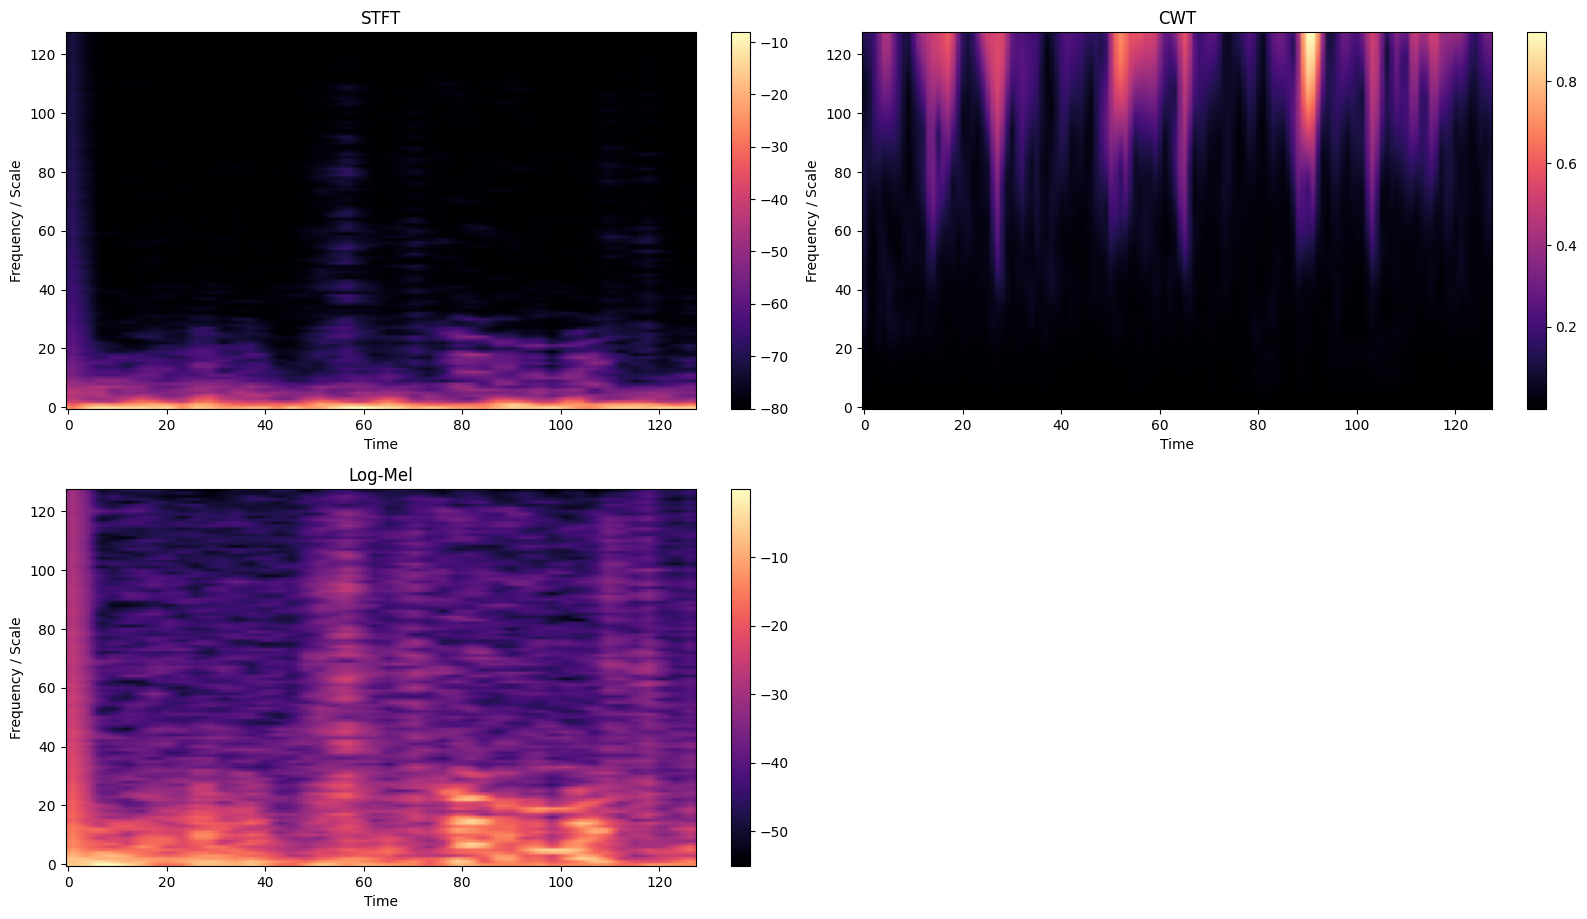

In [29]:
# ============================================================
# CELL 19 — VISUALIZE ALL SEVEN REPRESENTATIONS
# ============================================================

label = "Wheeze"

audio = examples[label]

features = extract_all_features(audio)

plt.figure(figsize=(16, 18))

for i, (name, feature) in enumerate(features.items()):

    plt.subplot(4, 2, i + 1)

    if feature.ndim == 3:

        # Display first channel
        image = feature[:, :, 0]

    else:

        image = feature

    plt.imshow(
        image,
        aspect="auto",
        origin="lower",
        cmap="magma"
    )

    plt.title(name)
    plt.xlabel("Time")
    plt.ylabel("Frequency / Scale")

    plt.colorbar(fraction=0.046)

plt.tight_layout()
plt.show()

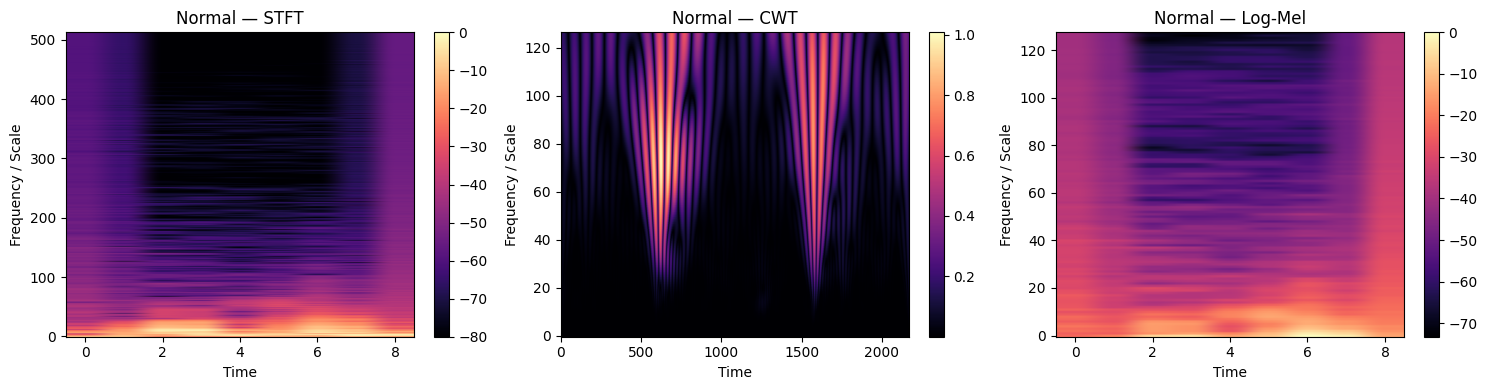

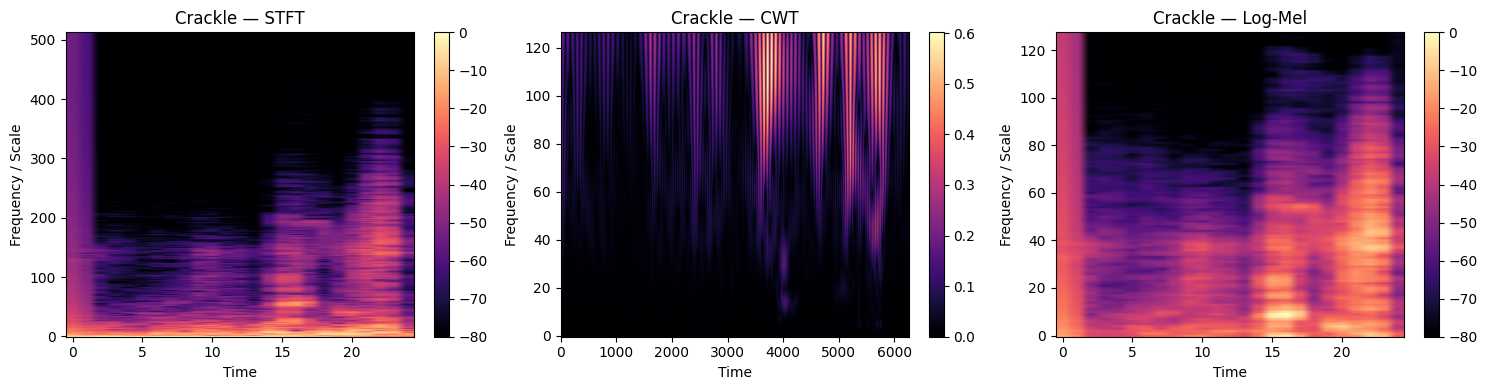

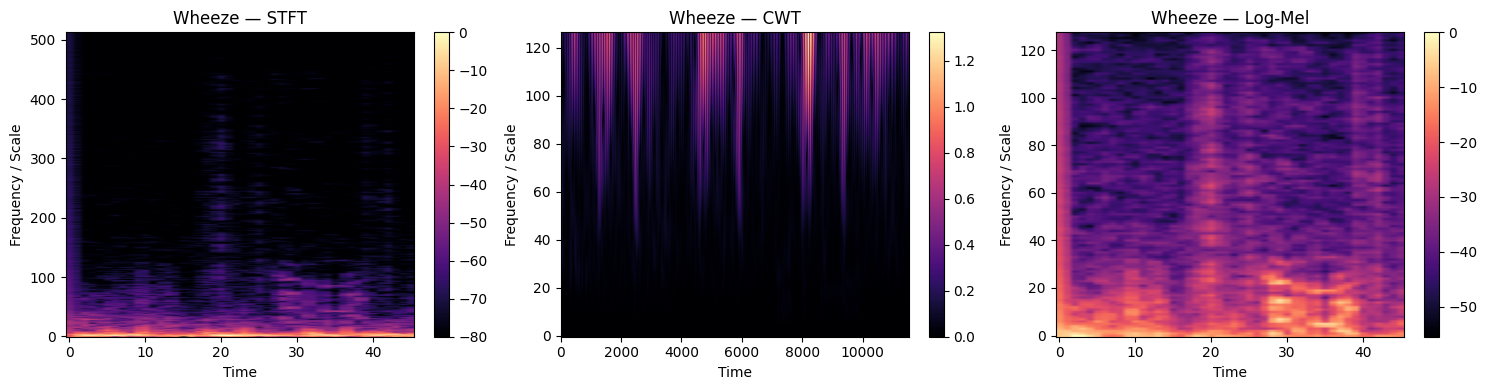

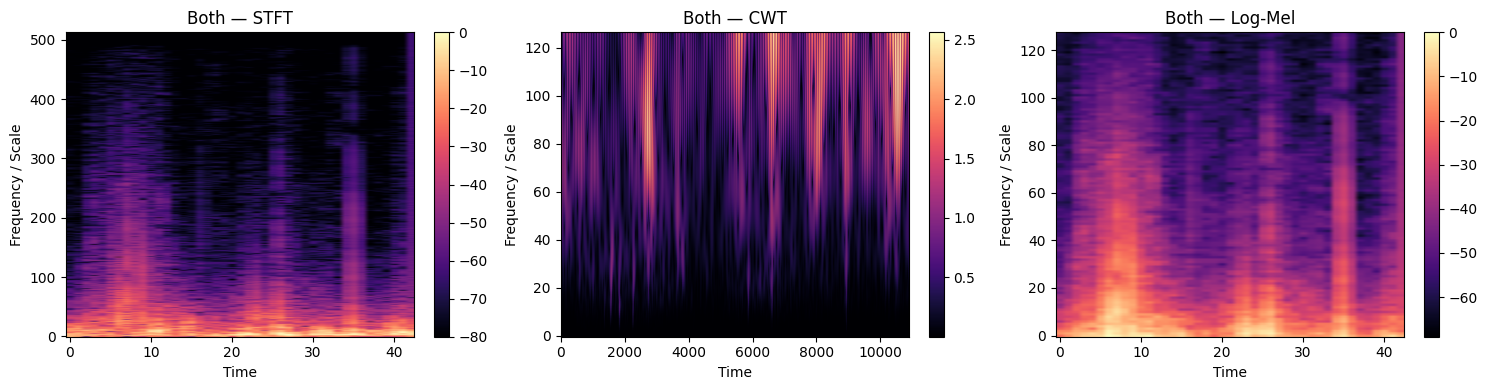

In [30]:
# ============================================================
# CELL 20 — VISUALIZE STFT / CWT / LOG-MEL
# FOR ALL FOUR CLASSES
# ============================================================

for label in CLASS_NAMES:

    audio = examples[label]

    # --------------------------------------------------------
    # 1. Extract features
    # --------------------------------------------------------

    stft = extract_stft(audio)

    # CWT returns TWO things:
    #   1. CWT magnitude
    #   2. CWT frequencies
    cwt, cwt_frequencies = extract_cwt(audio)

    logmel = extract_logmel(audio)

    # --------------------------------------------------------
    # 2. Prepare representations
    # --------------------------------------------------------

    representations = [
        ("STFT", stft),
        ("CWT", cwt),
        ("Log-Mel", logmel)
    ]

    # --------------------------------------------------------
    # 3. Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4)
    )

    # --------------------------------------------------------
    # 4. Plot
    # --------------------------------------------------------

    for ax, (name, feature) in zip(
        axes,
        representations
    ):

        im = ax.imshow(
            feature,
            aspect="auto",
            origin="lower",
            cmap="magma"
        )

        ax.set_title(
            f"{label} — {name}"
        )

        ax.set_xlabel("Time")
        ax.set_ylabel("Frequency / Scale")

        fig.colorbar(
            im,
            ax=ax,
            fraction=0.046
        )

    plt.tight_layout()
    plt.show()

In [31]:
# ============================================================
# CELL 21 — COMPUTE CLASS WEIGHTS
# ============================================================

import numpy as np

class_indices = {
    name: i
    for i, name in enumerate(CLASS_NAMES)
}

y_train = train_df["label"].map(class_indices).values

# Create an array of 1.0 for every class
weights = np.ones(NUM_CLASSES)

class_weights = {
    i: float(w)
    for i, w in enumerate(weights)
}

print("Class weights:")

for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name:10s}: "
        f"{class_weights[i]:.3f}"
    )

Class weights:
Normal    : 1.000
Crackle   : 1.000
Wheeze    : 1.000
Both      : 1.000


In [32]:
# ============================================================
# CELL 22 — AUDIO AUGMENTATION
# ============================================================

def augment_audio(audio):

    augmented = audio.copy()

    # --------------------------------------------------------
    # 1. Random gain
    # --------------------------------------------------------

    gain = np.random.uniform(
        0.90,
        1.10
    )

    augmented = augmented * gain


    # --------------------------------------------------------
    # 2. Small time shift
    # --------------------------------------------------------

    shift = np.random.randint(
        -int(0.05 * TARGET_SR),
        int(0.05 * TARGET_SR)
    )

    augmented = np.roll(
        augmented,
        shift
    )


    # --------------------------------------------------------
    # 3. Small Gaussian noise
    # --------------------------------------------------------

    noise_level = 0.005 * np.std(
        augmented
    )

    noise = np.random.normal(
        0,
        noise_level,
        size=augmented.shape
    )

    augmented = augmented + noise


    # --------------------------------------------------------
    # Prevent clipping
    # --------------------------------------------------------

    max_value = np.max(
        np.abs(augmented)
    )

    if max_value > 1:
        augmented = (
            augmented / max_value
        )

    return augmented.astype(np.float32)

In [33]:
# ============================================================
# CELL 24 — FOCAL LOSS
# ============================================================

import tensorflow as tf

def focal_loss(
    gamma=2.0,
    alpha=None
):

    if alpha is None:
        alpha = tf.ones(
            NUM_CLASSES,
            dtype=tf.float32
        )

    alpha = tf.constant(
        alpha,
        dtype=tf.float32
    )

    def loss(y_true, y_pred):

        y_true = tf.cast(
            y_true,
            tf.int32
        )

        y_one_hot = tf.one_hot(
            y_true,
            depth=NUM_CLASSES
        )

        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1.0 - 1e-7
        )

        pt = tf.reduce_sum(
            y_one_hot * y_pred,
            axis=-1
        )

        alpha_t = tf.reduce_sum(
            y_one_hot * alpha,
            axis=-1
        )

        focal_term = tf.pow(
            1.0 - pt,
            gamma
        )

        ce = -tf.math.log(pt)

        return tf.reduce_mean(
            alpha_t * focal_term * ce
        )

    return loss

In [34]:
# ============================================================
# CELL 25 — BASELINE CNN
# ============================================================

from tensorflow.keras import layers, models


def build_baseline_cnn(
    input_shape=(128, 128, 3)
):

    model = models.Sequential([

        layers.Input(
            shape=input_shape
        ),

        # ----------------------------------------------------
        # Block 1
        # ----------------------------------------------------

        layers.Conv2D(
            32,
            (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.ReLU(),

        layers.MaxPooling2D(
            (2, 2)
        ),

        layers.Dropout(0.20),


        # ----------------------------------------------------
        # Block 2
        # ----------------------------------------------------

        layers.Conv2D(
            64,
            (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.ReLU(),

        layers.MaxPooling2D(
            (2, 2)
        ),

        layers.Dropout(0.25),


        # ----------------------------------------------------
        # Block 3
        # ----------------------------------------------------

        layers.Conv2D(
            128,
            (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.ReLU(),

        layers.MaxPooling2D(
            (2, 2)
        ),

        layers.Dropout(0.30),


        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.40),

        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])

    return model

In [35]:
# ============================================================
# CELL 26 — COMPILE BASELINE CNN
# ============================================================

model = build_baseline_cnn()

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss=focal_loss(
        gamma=2.0,
        alpha=weights
    ),

    metrics=[
        "accuracy"
    ]
)

model.summary()

I0000 00:00:1790542752.509117      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790542752.512243      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

In [36]:
def create_label(row):

    crackle = int(row["crackle"])
    wheeze = int(row["wheeze"])

    if crackle == 0 and wheeze == 0:
        return 0       # Normal

    elif crackle == 1 and wheeze == 0:
        return 1       # Crackle

    elif crackle == 0 and wheeze == 1:
        return 2       # Wheeze

    elif crackle == 1 and wheeze == 1:
        return 3       # Both

In [37]:
train_df["label"] = train_df.apply(create_label, axis=1)
val_df["label"] = val_df.apply(create_label, axis=1)
test_df["label"] = test_df.apply(create_label, axis=1)

In [38]:
print("Train labels:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation labels:")
print(val_df["label"].value_counts().sort_index())

print("\nTest labels:")
print(test_df["label"].value_counts().sort_index())

Train labels:
label
0    2257
1     832
2     491
3     220
Name: count, dtype: int64

Validation labels:
label
0    585
1    515
2    171
3    124
Name: count, dtype: int64

Test labels:
label
0    800
1    517
2    224
3    162
Name: count, dtype: int64


In [39]:
def oversample_dataframe(
    df,
    label_col="label",
    seed=SEED,
    cap_ratio=2.5,
    majority_augment_frac=0.15
):
    """
    Balances class counts via duplication, with two changes
    versus naive "duplicate minority up to majority count":

    1. cap_ratio - a very rare class (e.g. Both) is capped at
       cap_ratio x its own original count, instead of being
       forced all the way up to the majority count. Forcing a
       162-sample class up to an 800-sample target means ~80%
       of what the model sees for that class is duplicated/
       augmented copies of a small original pool - that invites
       overfitting to a handful of augmented variants rather
       than real diversity.

    2. majority_augment_frac - the majority class (deficit=0)
       still gets a modest slice of its OWN rows duplicated and
       augmented. Previously only minority classes received any
       augmentation, so the model learned tight/narrow decision
       regions for the majority class and fuzzy/robust regions
       for the (heavily augmented) minority classes - which
       tends to make the model under-predict the majority class
       at test time, even though raw counts came out "balanced".
    """

    df = df.copy()
    df["augment"] = False

    counts = df[label_col].value_counts()
    max_count = counts.max()

    balanced_parts = [df]

    for label_value, count in counts.items():

        deficit = max_count - count
        if deficit > 0:
            n_extra = min(deficit, int(count * cap_ratio))
        else:
            n_extra = int(count * majority_augment_frac)

        if n_extra <= 0:
            continue

        class_rows = df[df[label_col] == label_value]

        sampled = class_rows.sample(
            n=n_extra,
            replace=True,
            random_state=seed
        ).copy()

        sampled["augment"] = True

        balanced_parts.append(sampled)

    balanced_df = pd.concat(
        balanced_parts,
        ignore_index=True
    )

    balanced_df = balanced_df.sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)

    return balanced_df


train_df_balanced = oversample_dataframe(train_df, label_col="label")

val_df = val_df.copy()
val_df["augment"] = False

test_df = test_df.copy()
test_df["augment"] = False

print("\nBalanced train label counts:")
print(train_df_balanced["label"].value_counts().sort_index())


Balanced train label counts:
label
0    2595
1    2257
2    1718
3     770
Name: count, dtype: int64


In [40]:
# ============================================================
# ICBHI CACHED GENERATOR
# Supports:
#   STFT
#   CWT
#   Log-Mel
#   STFT+CWT
#   STFT+Log-Mel
#   CWT+Log-Mel
#   STFT+CWT+Log-Mel
#
# Separate cache for:
#   train / val / test
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.utils import Sequence
from tqdm.auto import tqdm


class ICBHICachedGenerator(Sequence):

    def __init__(
        self,
        df,
        feature_type="STFT",
        batch_size=32,
        cache_dir="/kaggle/working/ICBHI_FEATURE_CACHE",
        split_name="train",
        shuffle=True
    ):

        # ----------------------------------------------------
        # DATAFRAME
        # ----------------------------------------------------

        self.df = df.reset_index(drop=True)

        self.feature_type = feature_type
        self.batch_size = batch_size
        self.split_name = split_name
        self.shuffle = shuffle

        # ----------------------------------------------------
        # LABEL MAP
        # ----------------------------------------------------

        self.label_map = {
            "Normal": 0,
            "Crackle": 1,
            "Wheeze": 2,
            "Both": 3
        }

        # ----------------------------------------------------
        # SUPPORTED FEATURES
        # ----------------------------------------------------

        self.supported_features = [
            "STFT",
            "CWT",
            "Log-Mel",
            "STFT+CWT",
            "STFT+Log-Mel",
            "CWT+Log-Mel",
            "STFT+CWT+Log-Mel"
        ]

        if self.feature_type not in self.supported_features:

            raise ValueError(
                f"Unsupported feature type: "
                f"{self.feature_type}\n"
                f"Supported types: "
                f"{self.supported_features}"
            )

        # ----------------------------------------------------
        # CACHE DIRECTORY
        # ----------------------------------------------------

        self.cache_dir = os.path.join(
            cache_dir,
            feature_type.replace(" ", "_"),
            split_name
        )

        os.makedirs(
            self.cache_dir,
            exist_ok=True
        )

        # ----------------------------------------------------
        # CACHE FILES
        # ----------------------------------------------------

        self.X_cache = os.path.join(
            self.cache_dir,
            "features.npy"
        )

        self.y_cache = os.path.join(
            self.cache_dir,
            "labels.npy"
        )

        # ----------------------------------------------------
        # CHECK CACHE
        # ----------------------------------------------------

        cache_complete = (
            os.path.exists(self.X_cache)
            and
            os.path.exists(self.y_cache)
        )

        # ----------------------------------------------------
        # CREATE CACHE IF NEEDED
        # ----------------------------------------------------

        if not cache_complete:

            print("\n" + "=" * 60)

            print(
                f"Cache not found for "
                f"{feature_type} / {split_name}"
            )

            print("=" * 60)

            self._precompute_features()

        else:

            # ------------------------------------------------
            # CHECK CACHE SIZE
            # ------------------------------------------------

            cached_y = np.load(
                self.y_cache,
                mmap_mode="r"
            )

            if len(cached_y) != len(self.df):

                print("\n" + "=" * 60)

                print(
                    "Existing cache has wrong size!"
                )

                print(
                    f"DataFrame samples : "
                    f"{len(self.df)}"
                )

                print(
                    f"Cached samples    : "
                    f"{len(cached_y)}"
                )

                print("=" * 60)

                print(
                    "Rebuilding cache..."
                )

                os.remove(
                    self.X_cache
                )

                os.remove(
                    self.y_cache
                )

                self._precompute_features()

            else:

                print("\n" + "=" * 60)

                print(
                    f"Using existing cache: "
                    f"{feature_type} / {split_name}"
                )

                print("=" * 60)

                print(
                    self.cache_dir
                )

        # ----------------------------------------------------
        # LOAD CACHE
        # ----------------------------------------------------

        self.X = np.load(
            self.X_cache,
            mmap_mode="r"
        )

        self.y = np.load(
            self.y_cache
        )

        # ----------------------------------------------------
        # SAFETY CHECK
        # ----------------------------------------------------

        if len(self.X) != len(self.y):

            raise ValueError(
                f"Feature/label mismatch: "
                f"X={len(self.X)}, "
                f"y={len(self.y)}"
            )

        if len(self.df) != len(self.y):

            raise ValueError(
                f"DataFrame/cache mismatch: "
                f"DataFrame={len(self.df)}, "
                f"cache={len(self.y)}"
            )

        # ----------------------------------------------------
        # INFORMATION
        # ----------------------------------------------------

        print("\nCached dataset:")

        print(
            "Split:",
            self.split_name
        )

        print(
            "Feature:",
            self.feature_type
        )

        print(
            "X shape:",
            self.X.shape
        )

        print(
            "y shape:",
            self.y.shape
        )

        print(
            "Labels:",
            np.unique(self.y)
        )

        # ----------------------------------------------------
        # INDICES
        # ----------------------------------------------------

        self.indices = np.arange(
            len(self.df)
        )

        self.on_epoch_end()


    # ========================================================
    # FEATURE NORMALIZATION
    # ========================================================

    def _normalize_feature(
        self,
        feature
    ):

        feature = np.asarray(
            feature,
            dtype=np.float32
        )

        min_value = feature.min()

        max_value = feature.max()

        if max_value > min_value:

            feature = (
                feature - min_value
            ) / (
                max_value - min_value
            )

        else:

            feature = np.zeros_like(
                feature
            )

        return feature.astype(
            np.float32
        )


    # ========================================================
    # EXTRACT FEATURES
    # ========================================================

    def _extract_features(
        self,
        cycle
    ):

        # ----------------------------------------------------
        # STFT
        # ----------------------------------------------------

        if self.feature_type == "STFT":

            feature = extract_stft(
                cycle
            )

            feature = resize_feature(
                feature
            )

            feature = self._normalize_feature(
                feature
            )

            feature = np.stack(
                [
                    feature,
                    feature,
                    feature
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # CWT
        # ----------------------------------------------------

        elif self.feature_type == "CWT":

            feature, _ = extract_cwt(
                cycle
            )

            feature = resize_feature(
                feature
            )

            feature = self._normalize_feature(
                feature
            )

            feature = np.stack(
                [
                    feature,
                    feature,
                    feature
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # LOG-MEL
        # ----------------------------------------------------

        elif self.feature_type == "Log-Mel":

            feature = extract_logmel(
                cycle
            )

            feature = resize_feature(
                feature
            )

            feature = self._normalize_feature(
                feature
            )

            feature = np.stack(
                [
                    feature,
                    feature,
                    feature
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # STFT + CWT
        # ----------------------------------------------------

        elif self.feature_type == "STFT+CWT":

            stft = extract_stft(
                cycle
            )

            cwt, _ = extract_cwt(
                cycle
            )

            stft = resize_feature(
                stft
            )

            cwt = resize_feature(
                cwt
            )

            stft = self._normalize_feature(
                stft
            )

            cwt = self._normalize_feature(
                cwt
            )

            # Third channel = average
            # of STFT and CWT

            third_channel = (
                stft + cwt
            ) / 2.0

            feature = np.stack(
                [
                    stft,
                    cwt,
                    third_channel
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # STFT + LOG-MEL
        # ----------------------------------------------------

        elif self.feature_type == "STFT+Log-Mel":

            stft = extract_stft(
                cycle
            )

            logmel = extract_logmel(
                cycle
            )

            stft = resize_feature(
                stft
            )

            logmel = resize_feature(
                logmel
            )

            stft = self._normalize_feature(
                stft
            )

            logmel = self._normalize_feature(
                logmel
            )

            # Third channel = average
            # of STFT and Log-Mel

            third_channel = (
                stft + logmel
            ) / 2.0

            feature = np.stack(
                [
                    stft,
                    logmel,
                    third_channel
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # CWT + LOG-MEL
        # ----------------------------------------------------

        elif self.feature_type == "CWT+Log-Mel":

            cwt, _ = extract_cwt(
                cycle
            )

            logmel = extract_logmel(
                cycle
            )

            cwt = resize_feature(
                cwt
            )

            logmel = resize_feature(
                logmel
            )

            cwt = self._normalize_feature(
                cwt
            )

            logmel = self._normalize_feature(
                logmel
            )

            # Third channel = average
            # of CWT and Log-Mel

            third_channel = (
                cwt + logmel
            ) / 2.0

            feature = np.stack(
                [
                    cwt,
                    logmel,
                    third_channel
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # STFT + CWT + LOG-MEL
        # ----------------------------------------------------

        elif self.feature_type == "STFT+CWT+Log-Mel":

            stft = extract_stft(
                cycle
            )

            cwt, _ = extract_cwt(
                cycle
            )

            logmel = extract_logmel(
                cycle
            )

            stft = resize_feature(
                stft
            )

            cwt = resize_feature(
                cwt
            )

            logmel = resize_feature(
                logmel
            )

            stft = self._normalize_feature(
                stft
            )

            cwt = self._normalize_feature(
                cwt
            )

            logmel = self._normalize_feature(
                logmel
            )

            feature = np.stack(
                [
                    stft,
                    cwt,
                    logmel
                ],
                axis=-1
            )

        # ----------------------------------------------------
        # SAFETY
        # ----------------------------------------------------

        else:

            raise ValueError(
                "Unknown feature type"
            )

        # ----------------------------------------------------
        # FINAL CHECK
        # ----------------------------------------------------

        feature = np.asarray(
            feature,
            dtype=np.float32
        )

        if feature.shape != (
            128,
            128,
            3
        ):

            raise ValueError(
                f"Unexpected feature shape: "
                f"{feature.shape}"
            )

        return feature


    # ========================================================
    # PRECOMPUTE FEATURES
    # ========================================================

    def _precompute_features(self):

        N = len(
            self.df
        )

        IMAGE_HEIGHT = 128
        IMAGE_WIDTH = 128
        CHANNELS = 3

        print("\nStarting precomputation...")

        print(
            "Split:",
            self.split_name
        )

        print(
            "Feature:",
            self.feature_type
        )

        print(
            "Samples:",
            N
        )

        # ----------------------------------------------------
        # MEMORY-MAPPED FEATURE FILE
        # ----------------------------------------------------

        X = np.lib.format.open_memmap(
            self.X_cache,
            mode="w+",
            dtype=np.float16,
            shape=(
                N,
                IMAGE_HEIGHT,
                IMAGE_WIDTH,
                CHANNELS
            )
        )

        # ----------------------------------------------------
        # LABEL ARRAY
        # ----------------------------------------------------

        y = np.zeros(
            N,
            dtype=np.int64
        )

        # ----------------------------------------------------
        # PROCESS EACH CYCLE
        # ----------------------------------------------------

        for i in tqdm(
            range(N),
            desc=(
                f"{self.split_name} - "
                f"{self.feature_type}"
            )
        ):

            row = self.df.iloc[i]

            # ------------------------------------------------
            # LOAD AUDIO
            # ------------------------------------------------

            audio, sr = (
                load_and_preprocess_audio(
                    row["file"]
                )
            )

            # ------------------------------------------------
            # CYCLE BOUNDARIES
            # ------------------------------------------------

            start_sample = int(
                row["start"] * sr
            )

            end_sample = int(
                row["end"] * sr
            )

            cycle = audio[
                start_sample:end_sample
            ]

            # ------------------------------------------------
            # EMPTY CYCLE CHECK
            # ------------------------------------------------

            if len(cycle) == 0:

                raise ValueError(
                    f"Empty cycle at index {i}"
                )

            # ------------------------------------------------
            # OPTIONAL AUGMENTATION
            # Applied only to rows flagged "augment"=True
            # (the duplicate rows created by oversampling).
            # Real/original rows and all val/test rows are
            # never augmented, so evaluation stays honest.
            # ------------------------------------------------

            if "augment" in self.df.columns and bool(row.get("augment", False)):

                cycle = augment_audio(cycle)

            # ------------------------------------------------
            # EXTRACT FEATURE
            # ------------------------------------------------

            feature = (
                self._extract_features(
                    cycle
                )
            )

            # ------------------------------------------------
            # SAVE FEATURE
            # ------------------------------------------------

            X[i] = feature.astype(
                np.float16
            )

            # ------------------------------------------------
            # LABEL
            # ------------------------------------------------

            label = row["label"]

            if isinstance(
                label,
                str
            ):

                if label not in self.label_map:

                    raise ValueError(
                        f"Unknown label: "
                        f"{label}"
                    )

                label = self.label_map[
                    label
                ]

            else:

                if np.isnan(label):

                    raise ValueError(
                        f"NaN label at "
                        f"index {i}"
                    )

                label = int(
                    label
                )

            # ------------------------------------------------
            # VALID LABEL CHECK
            # ------------------------------------------------

            if label not in [
                0,
                1,
                2,
                3
            ]:

                raise ValueError(
                    f"Invalid label {label} "
                    f"at index {i}"
                )

            y[i] = label

        # ----------------------------------------------------
        # FLUSH
        # ----------------------------------------------------

        X.flush()

        # ----------------------------------------------------
        # SAVE LABELS
        # ----------------------------------------------------

        np.save(
            self.y_cache,
            y
        )

        print(
            "\nPrecomputation complete!"
        )

        print(
            "Saved:",
            self.cache_dir
        )


    # ========================================================
    # NUMBER OF BATCHES
    # ========================================================

    def __len__(self):

        return int(
            np.ceil(
                len(self.indices)
                /
                self.batch_size
            )
        )


    # ========================================================
    # GET BATCH
    # ========================================================

    def __getitem__(
        self,
        index
    ):

        start = (
            index *
            self.batch_size
        )

        end = min(
            start +
            self.batch_size,
            len(self.indices)
        )

        batch_indices = (
            self.indices[
                start:end
            ]
        )

        # ----------------------------------------------------
        # FEATURES
        # ----------------------------------------------------

        X_batch = np.asarray(
            self.X[
                batch_indices
            ],
            dtype=np.float32
        )

        # ----------------------------------------------------
        # LABELS
        # ----------------------------------------------------

        y_batch = np.asarray(
            self.y[
                batch_indices
            ],
            dtype=np.int32
        )

        return (
            X_batch,
            y_batch
        )


    # ========================================================
    # SHUFFLE
    # ========================================================

    def on_epoch_end(self):

        if self.shuffle:

            np.random.shuffle(
                self.indices
            )

In [41]:
print("Unique train:", sorted(train_df["label"].unique()))
print("Unique val:", sorted(val_df["label"].unique()))
print("Unique test:", sorted(test_df["label"].unique()))

Unique train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Unique val: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Unique test: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [42]:
# ============================================================
# CELL — CONVERT FEATURE TO 3 CHANNELS
# ============================================================

def make_three_channel(feature):
    """
    Convert a feature image into 3 channels
    so it can be used with standard CNN architectures.
    """

    # Make sure it is a NumPy array
    feature = np.asarray(feature, dtype=np.float32)

    # --------------------------------------------------------
    # Case 1: Feature is grayscale (H, W)
    # --------------------------------------------------------
    if feature.ndim == 2:

        feature = np.stack(
            [feature, feature, feature],
            axis=-1
        )

    # --------------------------------------------------------
    # Case 2: Feature already has 3 channels (H, W, 3)
    # --------------------------------------------------------
    elif feature.ndim == 3 and feature.shape[-1] == 3:

        pass

    # --------------------------------------------------------
    # Case 3: Feature has 2 channels (H, W, 2)
    # --------------------------------------------------------
    elif feature.ndim == 3 and feature.shape[-1] == 2:

        third_channel = np.mean(
            feature,
            axis=-1,
            keepdims=True
        )

        feature = np.concatenate(
            [feature, third_channel],
            axis=-1
        )

    else:
        raise ValueError(
            f"Unexpected feature shape: {feature.shape}"
        )

    return feature.astype(np.float32)


Cache not found for STFT / train_balanced

Starting precomputation...
Split: train_balanced
Feature: STFT
Samples: 7340


train_balanced - STFT:   0%|          | 0/7340 [00:00<?, ?it/s]


Precomputation complete!
Saved: /kaggle/working/ICBHI_FEATURE_CACHE/STFT/train_balanced

Cached dataset:
Split: train_balanced
Feature: STFT
X shape: (7340, 128, 128, 3)
y shape: (7340,)
Labels: [0 1 2 3]


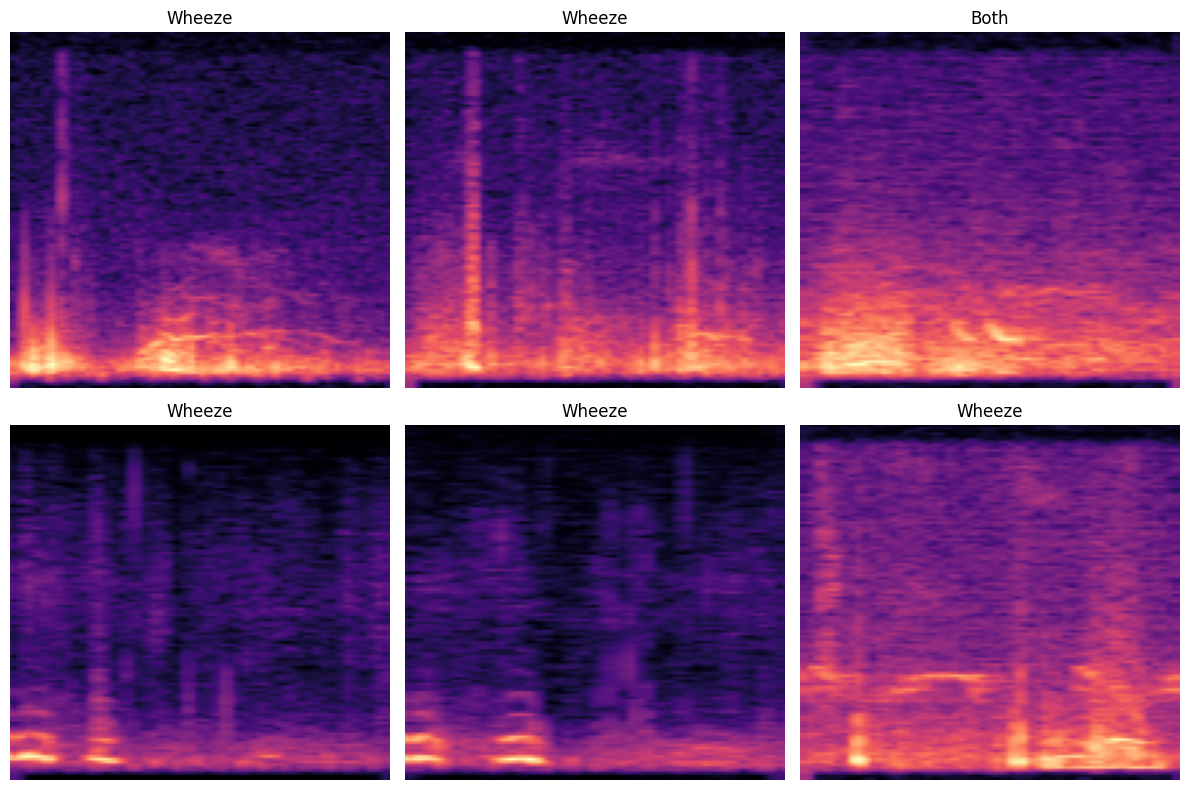

In [43]:
# ============================================================
# CELL 29 — VISUALIZE ACTUAL CNN INPUT
# ============================================================

# ------------------------------------------------------------
# X_batch / y_batch were never actually created before this
# point in the original notebook (this cell referenced them
# without defining them first) - pulling one batch here from
# the balanced training data fixes the NameError.
# ------------------------------------------------------------

_viz_feature_type = "STFT"

_viz_gen = ICBHICachedGenerator(
    train_df_balanced,
    feature_type=_viz_feature_type,
    batch_size=16,
    cache_dir="/kaggle/working/ICBHI_FEATURE_CACHE",
    split_name="train_balanced",
    shuffle=True
)

X_batch, y_batch = _viz_gen[0]

plt.figure(figsize=(12, 8))

for i in range(
    min(6, len(X_batch))
):

    plt.subplot(2, 3, i + 1)

    plt.imshow(
        X_batch[i, :, :, 0],
        aspect="auto",
        origin="lower",
        cmap="magma"
    )

    plt.title(
        CLASS_NAMES[y_batch[i]]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# CREATE TF.DATA DATASET
# ============================================================

train_ds = tf.data.Dataset.from_generator(
    lambda: train_gen,
    output_signature=(
        tf.TensorSpec(
            shape=(None, 128, 128, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.int32
        )
    )
)

train_ds = train_ds.prefetch(
    tf.data.AUTOTUNE
)

In [45]:
# ============================================================
# CELL 30 — TRAIN BASELINE CNN
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

FEATURE_TYPE = "STFT"

BATCH_SIZE = 16
EPOCHS = 20


# ------------------------------------------------------------
# TRAIN GENERATOR
# ------------------------------------------------------------

train_gen = ICBHICachedGenerator(
    train_df,
    feature_type=FEATURE_TYPE,
    batch_size=BATCH_SIZE,
    cache_dir="/kaggle/working/ICBHI_FEATURE_CACHE",
    split_name="train",
    shuffle=True
)
# ------------------------------------------------------------
# VALIDATION GENERATOR
# ------------------------------------------------------------

val_gen = ICBHICachedGenerator(
    val_df,
    feature_type=FEATURE_TYPE,
    batch_size=BATCH_SIZE,
    cache_dir="/kaggle/working/ICBHI_FEATURE_CACHE",
    split_name="val",
    shuffle=False
)


# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

model = build_baseline_cnn()


# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss=focal_loss(
        gamma=2.0,
        alpha=weights
    ),

    metrics=[
        "accuracy"
    ]
)


# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "/kaggle/working/best_baseline_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks
)


Cache not found for STFT / train

Starting precomputation...
Split: train
Feature: STFT
Samples: 3800


train - STFT:   0%|          | 0/3800 [00:00<?, ?it/s]


Precomputation complete!
Saved: /kaggle/working/ICBHI_FEATURE_CACHE/STFT/train

Cached dataset:
Split: train
Feature: STFT
X shape: (3800, 128, 128, 3)
y shape: (3800,)
Labels: [0 1 2 3]

Cache not found for STFT / val

Starting precomputation...
Split: val
Feature: STFT
Samples: 1395


val - STFT:   0%|          | 0/1395 [00:00<?, ?it/s]


Precomputation complete!
Saved: /kaggle/working/ICBHI_FEATURE_CACHE/STFT/val

Cached dataset:
Split: val
Feature: STFT
X shape: (1395, 128, 128, 3)
y shape: (1395,)
Labels: [0 1 2 3]
Epoch 1/20
  8/238 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.3592 - loss: 0.9049 

I0000 00:00:1790543046.939897     143 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 66/238 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4379 - loss: 0.7784

2026-09-27 21:04:09.262561: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-27 21:04:09.405942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


238/238 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.5192 - loss: 0.6167 - val_accuracy: 0.4194 - val_loss: 0.6472 - learning_rate: 1.0000e-04
Epoch 2/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5674 - loss: 0.5356 - val_accuracy: 0.4194 - val_loss: 0.6416 - learning_rate: 1.0000e-04
Epoch 3/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5811 - loss: 0.5228 - val_accuracy: 0.4194 - val_loss: 0.6347 - learning_rate: 1.0000e-04
Epoch 4/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5853 - loss: 0.5102 - val_accuracy: 0.4179 - val_loss: 0.6251 - learning_rate: 1.0000e-04
Epoch 5/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5889 - loss: 0.5064 - val_accuracy: 0.4165 - val_loss: 0.7006 - learning_rate: 1.0000e-04
Epoch 6/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5911 - loss: 0.5048 - val_accuracy: 0.4186 - val_loss: 0.6663 - learning_rate: 1.0000e-04
Epoch 7/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5

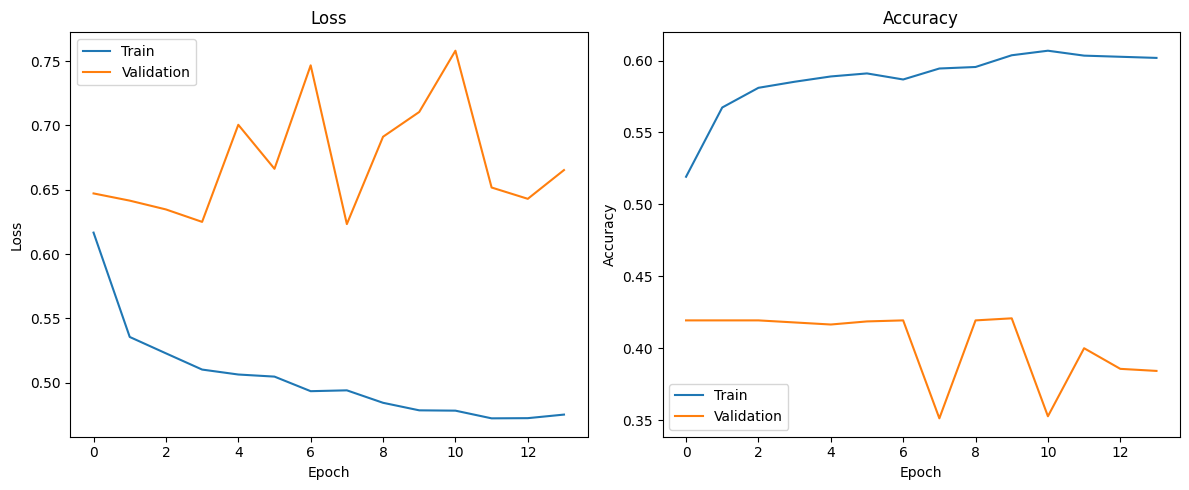

In [46]:
# ============================================================
# CELL 31 — TRAINING CURVES
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["loss"],
    label="Train"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.title("Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["accuracy"],
    label="Train"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.title("Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.tight_layout()

plt.show()

In [47]:
# ============================================================
# CELL 32 — TEST SET EVALUATION
# ============================================================

test_gen = ICBHICachedGenerator(
    test_df,
    feature_type=FEATURE_TYPE,
    batch_size=BATCH_SIZE,
    cache_dir="/kaggle/working/ICBHI_FEATURE_CACHE",
    split_name="test",
    shuffle=False
)

test_loss, test_accuracy = model.evaluate(
    test_gen
)

print(
    f"Test loss: {test_loss:.4f}"
)

print(
    f"Test accuracy: {test_accuracy:.4f}"
)


Cache not found for STFT / test

Starting precomputation...
Split: test
Feature: STFT
Samples: 1703


test - STFT:   0%|          | 0/1703 [00:00<?, ?it/s]


Precomputation complete!
Saved: /kaggle/working/ICBHI_FEATURE_CACHE/STFT/test

Cached dataset:
Split: test
Feature: STFT
X shape: (1703, 128, 128, 3)
y shape: (1703,)
Labels: [0 1 2 3]
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4844 - loss: 0.6027
Test loss: 0.6027
Test accuracy: 0.4844


In [48]:
# Print lengths of all dataset splits
print(f"Original train length: {len(train_df):,}")
print(f"Balanced train length: {len(train_df_balanced):,}")
print(f"Validation length:     {len(val_df):,}")
print(f"Test length:           {len(test_df):,}")

print("\nBalanced train label counts:")
print(train_df_balanced["label"].value_counts().sort_index())

Original train length: 3,800
Balanced train length: 7,340
Validation length:     1,395
Test length:           1,703

Balanced train label counts:
label
0    2595
1    2257
2    1718
3     770
Name: count, dtype: int64


  0%|          | 0/107 [00:00<?, ?it/s]

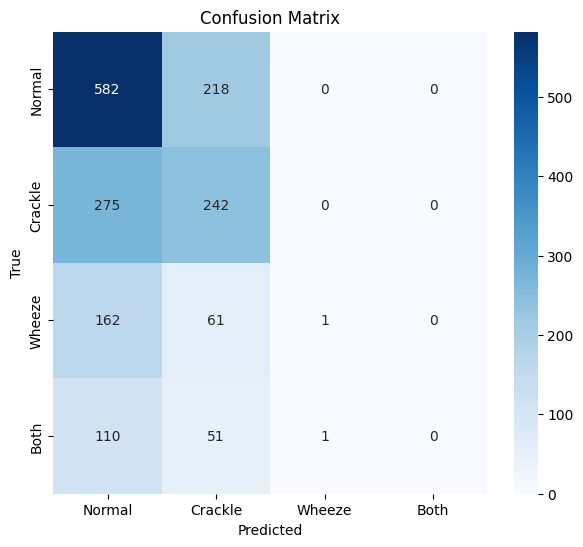

              precision    recall  f1-score   support

      Normal     0.5155    0.7275    0.6034       800
     Crackle     0.4231    0.4681    0.4444       517
      Wheeze     0.5000    0.0045    0.0088       224
        Both     0.0000    0.0000    0.0000       162

    accuracy                         0.4844      1703
   macro avg     0.3596    0.3000    0.2642      1703
weighted avg     0.4364    0.4844    0.4196      1703



In [49]:
# ============================================================
# CELL 33 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []


for i in tqdm(range(len(test_gen))):

    X_batch, y_batch = test_gen[i]

    predictions = model.predict(
        X_batch,
        verbose=0
    )

    predictions = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        y_batch
    )

    y_pred.extend(
        predictions
    )


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()


print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

## Two-Stage Cascade: Stage 1 (Normal vs Abnormal) -> Stage 2 (Crackle / Wheeze / Both)

Everything below is additive and does not change the single-stage baseline above.

- **Stage 1** — binary classifier (Normal vs Abnormal), trained on `STFT`.
- **Stage 2** — 3-class classifier (Crackle / Wheeze / Both), trained on `STFT+Log-Mel`, using only the truly-abnormal train cycles.
- **End-to-end evaluation** — runs the untouched test split through Stage 1, routes predicted-abnormal cycles into Stage 2, and reconstructs the final 4-class prediction to score against the true labels. A cycle Stage 1 misses as "Normal" never reaches Stage 2, so this is the number that reflects real cascade performance, not just per-stage accuracy.
- Oversampling (train-only, same `oversample_dataframe` used above) is applied separately within each stage's own training set to handle that stage's class imbalance.


In [50]:
# ============================================================
# CASCADE — SHARED IMPORTS
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report

tf.random.set_seed(SEED)

CASCADE_BATCH_SIZE = BATCH_SIZE
CASCADE_EPOCHS = EPOCHS


def build_cnn(num_classes, input_shape=(128, 128, 3)):
    """Same architecture as build_baseline_cnn, but with a
    parameterized number of output classes so it can be reused
    for the binary Stage 1 model and the 3-class Stage 2 model."""

    model = models.Sequential([

        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.20),

        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),
        layers.Dense(num_classes, activation="softmax")
    ])

    return model


### Stage 1 — Normal vs Abnormal

In [113]:
# ============================================================
# STAGE 1 — DATA PREP (binary: 0=Normal, 1=Abnormal)
# ============================================================

# ============================================================
# STAGE 1 — DATA PREP (binary: 0=Normal, 1=Abnormal)
# ============================================================



# ============================================================
# STAGE 1 — DATA PREP (binary: 0=Normal, 1=Abnormal)
# No oversampling, no class weighting - trains on the real,
# unmodified class distribution.
# ============================================================

STAGE1_FEATURE_TYPE = "STFT+Log-Mel"
STAGE1_CACHE_DIR = "/kaggle/working/ICBHI_FEATURE_CACHE_STAGE1"
STAGE1_CLASS_NAMES = ["Normal", "Abnormal"]
STAGE1_NUM_CLASSES = 2


def make_stage1_df(df):
    out = df.copy()
    out["orig_label"] = out["label"]
    out["label"] = (out["orig_label"] != 0).astype(int)
    return out


stage1_train_df = make_stage1_df(train_df)
stage1_val_df = make_stage1_df(val_df)
stage1_test_df = make_stage1_df(test_df)

print("Stage 1 real (unbalanced) train label counts:")
print(stage1_train_df["label"].value_counts().sort_index())

Stage 1 real (unbalanced) train label counts:
label
0    2257
1    1543
Name: count, dtype: int64


In [114]:
# ============================================================
# STAGE 1 — TRAIN
# ============================================================

stage1_train_gen = ICBHICachedGenerator(
    stage1_train_df,
    feature_type=STAGE1_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE1_CACHE_DIR,
    split_name="train",
    shuffle=True
)

stage1_val_gen = ICBHICachedGenerator(
    stage1_val_df,
    feature_type=STAGE1_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE1_CACHE_DIR,
    split_name="val",
    shuffle=False
)

NUM_CLASSES = 2   # sets build_baseline_cnn()'s output layer size - this is
                  # architecture, not imbalance-handling, so it has to stay

stage1_model = build_baseline_cnn()

stage1_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",   # plain loss - no alpha/class weighting
    metrics=["accuracy"]
)

stage1_callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint("/content/best_stage1_cnn.keras", monitor="val_loss", save_best_only=True)
]

stage1_history = stage1_model.fit(
    stage1_train_gen,
    validation_data=stage1_val_gen,
    epochs=CASCADE_EPOCHS,
    callbacks=stage1_callbacks
)



Using existing cache: STFT+Log-Mel / train
/kaggle/working/ICBHI_FEATURE_CACHE_STAGE1/STFT+Log-Mel/train

Cached dataset:
Split: train
Feature: STFT+Log-Mel
X shape: (3800, 128, 128, 3)
y shape: (3800,)
Labels: [0 1]

Using existing cache: STFT+Log-Mel / val
/kaggle/working/ICBHI_FEATURE_CACHE_STAGE1/STFT+Log-Mel/val

Cached dataset:
Split: val
Feature: STFT+Log-Mel
X shape: (1395, 128, 128, 3)
y shape: (1395,)
Labels: [0 1]
Epoch 1/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 19s 45ms/step - accuracy: 0.5632 - loss: 0.7120 - val_accuracy: 0.5806 - val_loss: 0.6821 - learning_rate: 1.0000e-04
Epoch 2/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5832 - loss: 0.6686 - val_accuracy: 0.6108 - val_loss: 0.6793 - learning_rate: 1.0000e-04
Epoch 3/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6029 - loss: 0.6657 - val_accuracy: 0.6165 - val_loss: 0.6699 - learning_rate: 1.0000e-04
Epoch 4/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6108 - loss: 0.6541 - val_accur

In [115]:
stage1_val_probs = stage1_model.predict(
    stage1_val_gen,
    verbose=0
)

stage1_val_abnormal_prob = stage1_val_probs[:, 1]
stage1_val_true = stage1_val_df["label"].values

In [116]:
# ============================================================
# TEST DIFFERENT THRESHOLDS
# ============================================================

thresholds = np.arange(0.50, 0.71, 0.01)

best_threshold = None
best_macro_f1 = -1

for threshold in thresholds:

    val_preds = (
        stage1_val_abnormal_prob >= threshold
    ).astype(int)

    report = classification_report(
        stage1_val_true,
        val_preds,
        target_names=STAGE1_CLASS_NAMES,
        output_dict=True
    )

    macro_f1 = report["macro avg"]["f1-score"]

    print(
        f"Threshold = {threshold:.2f} | "
        f"Macro F1 = {macro_f1:.4f}"
    )

    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_threshold = threshold

print("\nBest threshold:", best_threshold)
print("Best validation Macro F1:", best_macro_f1)

Threshold = 0.50 | Macro F1 = 0.5525
Threshold = 0.51 | Macro F1 = 0.5736
Threshold = 0.52 | Macro F1 = 0.5831
Threshold = 0.53 | Macro F1 = 0.5802
Threshold = 0.54 | Macro F1 = 0.5673
Threshold = 0.55 | Macro F1 = 0.5486
Threshold = 0.56 | Macro F1 = 0.5215
Threshold = 0.57 | Macro F1 = 0.4856
Threshold = 0.58 | Macro F1 = 0.4563
Threshold = 0.59 | Macro F1 = 0.4399
Threshold = 0.60 | Macro F1 = 0.4210
Threshold = 0.61 | Macro F1 = 0.3895
Threshold = 0.62 | Macro F1 = 0.3596
Threshold = 0.63 | Macro F1 = 0.3481
Threshold = 0.64 | Macro F1 = 0.3323
Threshold = 0.65 | Macro F1 = 0.3276
Threshold = 0.66 | Macro F1 = 0.3188
Threshold = 0.67 | Macro F1 = 0.3170
Threshold = 0.68 | Macro F1 = 0.3176
Threshold = 0.69 | Macro F1 = 0.3149
Threshold = 0.70 | Macro F1 = 0.3083

Best threshold: 0.52
Best validation Macro F1: 0.5830898879361621


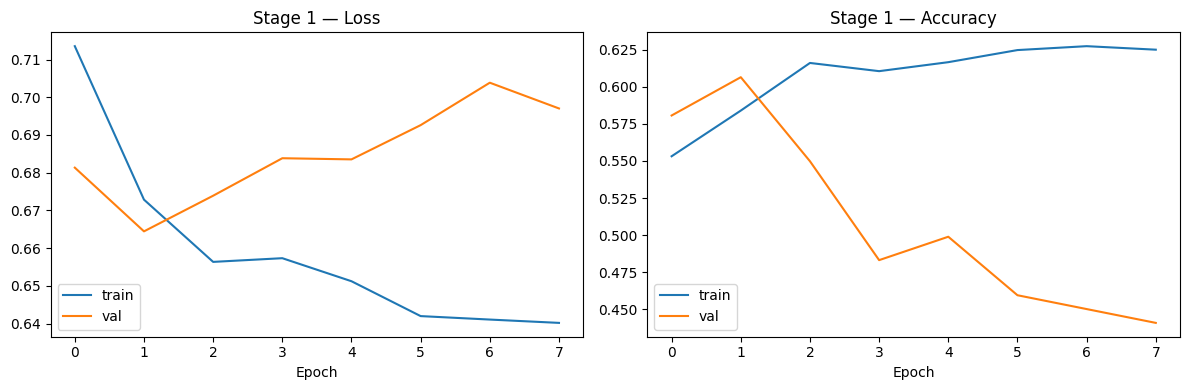

Stage 1 val prediction distribution: {np.int64(0): np.int64(48), np.int64(1): np.int64(1347)}


In [102]:
# ============================================================
# STAGE 1 — TRAINING CURVES (sanity check before evaluating)
# ============================================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(stage1_history.history["loss"], label="train")
plt.plot(stage1_history.history["val_loss"], label="val")
plt.title("Stage 1 — Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(stage1_history.history["accuracy"], label="train")
plt.plot(stage1_history.history["val_accuracy"], label="val")
plt.title("Stage 1 — Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

# Quick collapse check: what does stage 1 predict on the
# validation set right after training? If val predictions are
# almost all one class here too, the problem is real training
# instability - not just a stale-weights bug.
stage1_val_probs = stage1_model.predict(stage1_val_gen, verbose=0)
stage1_val_preds = np.argmax(stage1_val_probs, axis=1)
print("Stage 1 val prediction distribution:",
      dict(zip(*np.unique(stage1_val_preds, return_counts=True))))


### Stage 2 — Abnormal subtype (Crackle / Wheeze / Both)

In [118]:
# ============================================================
# STAGE 2 — DATA PREP (3-class, abnormal cycles only)
# 0=Crackle, 1=Wheeze, 2=Both  (remapped from original 1,2,3)
# ============================================================

STAGE2_FEATURE_TYPE = "STFT+Log-Mel"
STAGE2_CACHE_DIR = "/content/ICBHI_FEATURE_CACHE_STAGE2"
STAGE2_CLASS_NAMES = ["Crackle", "Wheeze", "Both"]
STAGE2_NUM_CLASSES = 3


def make_stage2_df(df):
    out = df[df["label"] != 0].copy()
    out["orig_label"] = out["label"]
    out["label"] = out["orig_label"] - 1
    return out


stage2_train_df = make_stage2_df(train_df)
stage2_val_df = make_stage2_df(val_df)
stage2_test_df = make_stage2_df(test_df)

stage2_train_df_balanced = oversample_dataframe(stage2_train_df, label_col="label")

stage2_val_df = stage2_val_df.copy()
stage2_val_df["augment"] = False

stage2_test_df = stage2_test_df.copy()
stage2_test_df["augment"] = False

print("Stage 2 balanced train label counts:")
print(stage2_train_df_balanced["label"].value_counts().sort_index())

stage2_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(STAGE2_NUM_CLASSES),
    y=stage2_train_df_balanced["label"].values
)

print("\nStage 2 class weights:")
for i, name in enumerate(STAGE2_CLASS_NAMES):
    print(f"{name:10s}: {stage2_weights[i]:.3f}")


Stage 2 balanced train label counts:
label
0    956
1    832
2    770
Name: count, dtype: int64

Stage 2 class weights:
Crackle   : 0.892
Wheeze    : 1.025
Both      : 1.107


In [119]:
# ============================================================
# STAGE 2 — TRAIN
# ============================================================
stage2_train_gen = ICBHICachedGenerator(
    stage2_train_df_balanced,
    feature_type=STAGE2_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE2_CACHE_DIR,
    split_name="train_balanced",
    shuffle=True
)

stage2_val_gen = ICBHICachedGenerator(
    stage2_val_df,
    feature_type=STAGE2_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE2_CACHE_DIR,
    split_name="val",
    shuffle=False
)

NUM_CLASSES = 3

stage2_model = build_baseline_cnn()

stage2_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=focal_loss(gamma=2.0, alpha=stage2_weights),
    metrics=["accuracy"]
)

stage2_callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint("/kaggle/working/best_stage2_cnn.keras", monitor="val_loss", save_best_only=True)
]

stage2_history = stage2_model.fit(
    stage2_train_gen,
    validation_data=stage2_val_gen,
    epochs=CASCADE_EPOCHS,
    callbacks=stage2_callbacks
)


Using existing cache: STFT+Log-Mel / train_balanced
/content/ICBHI_FEATURE_CACHE_STAGE2/STFT+Log-Mel/train_balanced

Cached dataset:
Split: train_balanced
Feature: STFT+Log-Mel
X shape: (2558, 128, 128, 3)
y shape: (2558,)
Labels: [0 1 2]

Using existing cache: STFT+Log-Mel / val
/content/ICBHI_FEATURE_CACHE_STAGE2/STFT+Log-Mel/val

Cached dataset:
Split: val
Feature: STFT+Log-Mel
X shape: (810, 128, 128, 3)
y shape: (810,)
Labels: [0 1 2]
Epoch 1/20
160/160 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 0.4390 - loss: 0.5236 - val_accuracy: 0.6358 - val_loss: 0.4398 - learning_rate: 1.0000e-04
Epoch 2/20
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.4793 - loss: 0.4566 - val_accuracy: 0.6358 - val_loss: 0.4147 - learning_rate: 1.0000e-04
Epoch 3/20
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5020 - loss: 0.4342 - val_accuracy: 0.6432 - val_loss: 0.3834 - learning_rate: 1.0000e-04
Epoch 4/20
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5301 - loss: 0.4

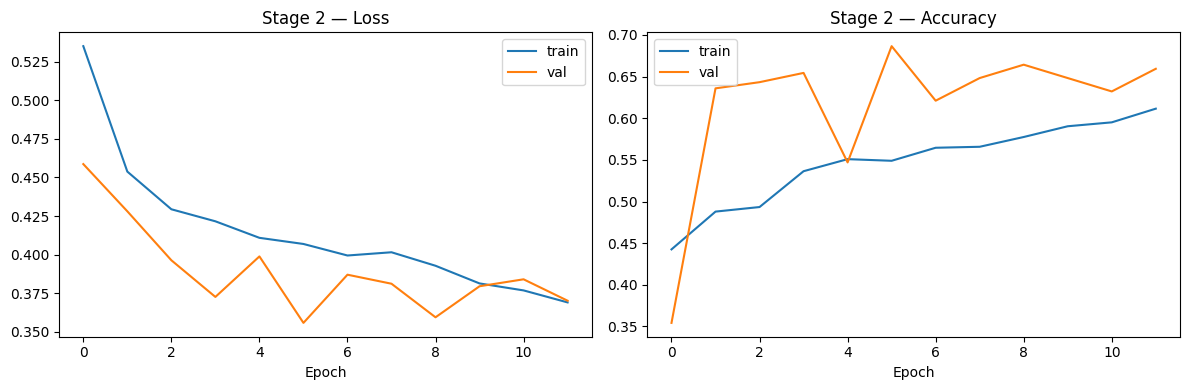

Stage 2 val prediction distribution: {np.int64(0): np.int64(728), np.int64(1): np.int64(78), np.int64(2): np.int64(4)}


In [105]:
# ============================================================
# STAGE 2 — TRAINING CURVES (sanity check before evaluating)
# ============================================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(stage2_history.history["loss"], label="train")
plt.plot(stage2_history.history["val_loss"], label="val")
plt.title("Stage 2 — Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(stage2_history.history["accuracy"], label="train")
plt.plot(stage2_history.history["val_accuracy"], label="val")
plt.title("Stage 2 — Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

stage2_val_probs = stage2_model.predict(stage2_val_gen, verbose=0)
stage2_val_preds = np.argmax(stage2_val_probs, axis=1)
print("Stage 2 val prediction distribution:",
      dict(zip(*np.unique(stage2_val_preds, return_counts=True))))


### Stage 1 -> Stage 2 end-to-end evaluation (on the untouched test split)

This is the pipeline-level result: every test cycle goes through Stage 1 first; only cycles predicted *Abnormal* are then passed to Stage 2. A Stage-1 mistake (e.g. an abnormal cycle called "Normal") can never be corrected by Stage 2, so this loop reconstructs the final 4-class prediction the same way the system would behave in practice, rather than scoring each stage in isolation.

In [120]:
# ============================================================
# STAGE 1 (standalone) — TEST METRICS
# ============================================================

stage1_test_gen = ICBHICachedGenerator(
    stage1_test_df,
    feature_type=STAGE1_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE1_CACHE_DIR,
    split_name="test",
    shuffle=False
)

# ------------------------------------------------------------
# Get probabilities
# ------------------------------------------------------------

stage1_test_probs = stage1_model.predict(
    stage1_test_gen,
    verbose=0
)

# ------------------------------------------------------------
# USE THE THRESHOLD SELECTED FROM VALIDATION
# ------------------------------------------------------------

STAGE1_THRESHOLD = 0.58  # <-- CHANGE THIS after validation testing

stage1_test_preds = (
    stage1_test_probs[:, 1] >= STAGE1_THRESHOLD
).astype(int)

stage1_test_true = stage1_test_df["label"].values


# ------------------------------------------------------------
# TEST RESULT
# ------------------------------------------------------------

print(
    f"Stage 1 standalone "
    f"(threshold = {STAGE1_THRESHOLD}):\n"
)

print(
    classification_report(
        stage1_test_true,
        stage1_test_preds,
        target_names=STAGE1_CLASS_NAMES,
        digits=4
    )
)


Using existing cache: STFT+Log-Mel / test
/kaggle/working/ICBHI_FEATURE_CACHE_STAGE1/STFT+Log-Mel/test

Cached dataset:
Split: test
Feature: STFT+Log-Mel
X shape: (1703, 128, 128, 3)
y shape: (1703,)
Labels: [0 1]
Stage 1 standalone (threshold = 0.58):

              precision    recall  f1-score   support

      Normal     0.5422    0.7063    0.6135       800
    Abnormal     0.6445    0.4718    0.5448       903

    accuracy                         0.5819      1703
   macro avg     0.5934    0.5890    0.5791      1703
weighted avg     0.5964    0.5819    0.5770      1703



In [121]:
# ============================================================
# STAGE 2 (standalone) — TEST METRICS
# Evaluated only on cycles that are TRULY abnormal, i.e. this
# is "if Stage 1 were perfect, how good is Stage 2 alone".
# ============================================================

stage2_test_gen = ICBHICachedGenerator(
    stage2_test_df,
    feature_type=STAGE2_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE2_CACHE_DIR,
    split_name="test",
    shuffle=False
)

stage2_test_probs = stage2_model.predict(stage2_test_gen, verbose=0)
stage2_test_preds = np.argmax(stage2_test_probs, axis=1)
stage2_test_true = stage2_test_df["label"].values

print("Stage 2 standalone (Crackle / Wheeze / Both, true-abnormal cycles only):\n")
print(classification_report(
    stage2_test_true,
    stage2_test_preds,
    target_names=STAGE2_CLASS_NAMES,
    digits=4
))



Using existing cache: STFT+Log-Mel / test
/content/ICBHI_FEATURE_CACHE_STAGE2/STFT+Log-Mel/test

Cached dataset:
Split: test
Feature: STFT+Log-Mel
X shape: (903, 128, 128, 3)
y shape: (903,)
Labels: [0 1 2]
Stage 2 standalone (Crackle / Wheeze / Both, true-abnormal cycles only):

              precision    recall  f1-score   support

     Crackle     0.6293    0.8569    0.7256       517
      Wheeze     0.4054    0.3348    0.3667       224
        Both     0.5000    0.0432    0.0795       162

    accuracy                         0.5814       903
   macro avg     0.5116    0.4116    0.3906       903
weighted avg     0.5505    0.5814    0.5207       903



In [122]:
print("Stage 1 test samples:", len(stage1_test_df))
print("Stage 2 test samples:", len(stage2_test_df))

print("\nFirst 10 Stage 2 rows:")
print(stage2_test_df[["file", "cycle_id", "label"]].head(10))

Stage 1 test samples: 1703
Stage 2 test samples: 903

First 10 Stage 2 rows:
                                                 file  cycle_id  label
56  /kaggle/input/datasets/vbookshelf/respiratory-...         8      0
65  /kaggle/input/datasets/vbookshelf/respiratory-...         0      2
66  /kaggle/input/datasets/vbookshelf/respiratory-...         1      0
67  /kaggle/input/datasets/vbookshelf/respiratory-...         2      2
68  /kaggle/input/datasets/vbookshelf/respiratory-...         3      0
69  /kaggle/input/datasets/vbookshelf/respiratory-...         4      0
71  /kaggle/input/datasets/vbookshelf/respiratory-...         6      1
72  /kaggle/input/datasets/vbookshelf/respiratory-...         7      1
73  /kaggle/input/datasets/vbookshelf/respiratory-...         8      1
74  /kaggle/input/datasets/vbookshelf/respiratory-...         9      1


In [123]:
print("Stage 1 index matches test_df:",
      np.array_equal(stage1_test_df.index.values, test_df.index.values))

print("Stage 2 indices are subset of test_df:",
      set(stage2_test_df.index).issubset(set(test_df.index)))

print("Number of Stage 2 rows:",
      len(stage2_test_df))

print("Number of unique Stage 2 indices:",
      stage2_test_df.index.nunique())

Stage 1 index matches test_df: True
Stage 2 indices are subset of test_df: True
Number of Stage 2 rows: 903
Number of unique Stage 2 indices: 903


In [125]:
cascade_stage2_test_df = stage1_test_df[
    stage1_test_preds == 1
].copy()

print("Cascade Stage 2 samples:", len(cascade_stage2_test_df))
print(cascade_stage2_test_df["label"].value_counts().sort_index())

Cascade Stage 2 samples: 661
label
0    235
1    426
Name: count, dtype: int64



Using existing cache: STFT+Log-Mel / test
/kaggle/working/ICBHI_FEATURE_CACHE_STAGE1/STFT+Log-Mel/test

Cached dataset:
Split: test
Feature: STFT+Log-Mel
X shape: (1703, 128, 128, 3)
y shape: (1703,)
Labels: [0 1]
Stage 1 predicted abnormal: 1075
Samples sent from Stage 1 to Stage 2: 1075

Using existing cache: STFT+Log-Mel / cascade_test
/content/ICBHI_FEATURE_CACHE_STAGE2/STFT+Log-Mel/cascade_test

Cached dataset:
Split: cascade_test
Feature: STFT+Log-Mel
X shape: (1075, 128, 128, 3)
y shape: (1075,)
Labels: [0 1]
Stage 2 predictions: 1075

Stage 1 -> Stage 2 cascade (full 4-class result on the test set):

              precision    recall  f1-score   support

      Normal     0.5637    0.4425    0.4958       800
     Crackle     0.3822    0.6054    0.4686       517
      Wheeze     0.2468    0.2545    0.2505       224
        Both     0.2800    0.0432    0.0749       162

    accuracy                         0.4292      1703
   macro avg     0.3682    0.3364    0.3224      1703
wei

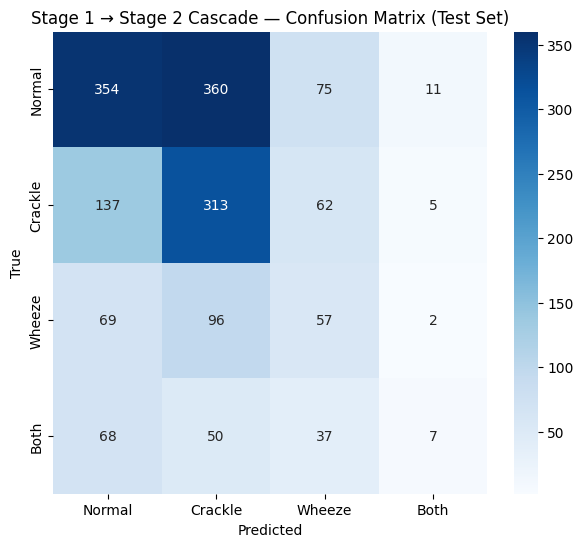

         Normal  Crackle  Wheeze  Both
Normal      354      360      75    11
Crackle     137      313      62     5
Wheeze       69       96      57     2
Both         68       50      37     7


In [128]:
# ============================================================
# FINAL CASCADE TEST
# Stage 1: Normal vs Abnormal
# Stage 2: Crackle vs Wheeze vs Both
# ============================================================

# ------------------------------------------------------------
# 1. STAGE 1 TEST PREDICTION
# ------------------------------------------------------------

stage1_eval_df = make_stage1_df(test_df)
stage1_eval_df["augment"] = False

stage1_eval_gen = ICBHICachedGenerator(
    stage1_eval_df,
    feature_type=STAGE1_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE1_CACHE_DIR,
    split_name="test",
    shuffle=False
)

stage1_probs = stage1_model.predict(
    stage1_eval_gen,
    verbose=0
)

# ------------------------------------------------------------
# USE THE THRESHOLD SELECTED FROM VALIDATION
# ------------------------------------------------------------

STAGE1_THRESHOLD = 0.55   # <-- your validation-selected threshold

stage1_preds = (
    stage1_probs[:, 1] >= STAGE1_THRESHOLD
).astype(int)

print("Stage 1 predicted abnormal:",
      np.sum(stage1_preds == 1))


# ------------------------------------------------------------
# 2. CREATE STAGE 2 DATASET ONLY FOR SAMPLES
#    THAT STAGE 1 PREDICTED AS ABNORMAL
# ------------------------------------------------------------

cascade_stage2_test_df = stage1_eval_df[
    stage1_preds == 1
].copy()

cascade_stage2_test_df["augment"] = False

print(
    "Samples sent from Stage 1 to Stage 2:",
    len(cascade_stage2_test_df)
)


# ------------------------------------------------------------
# 3. CREATE STAGE 2 GENERATOR
# ------------------------------------------------------------

cascade_stage2_test_gen = ICBHICachedGenerator(
    cascade_stage2_test_df,
    feature_type=STAGE2_FEATURE_TYPE,
    batch_size=CASCADE_BATCH_SIZE,
    cache_dir=STAGE2_CACHE_DIR,
    split_name="cascade_test",
    shuffle=False
)


# ------------------------------------------------------------
# 4. STAGE 2 PREDICTION
# ------------------------------------------------------------

cascade_stage2_probs = stage2_model.predict(
    cascade_stage2_test_gen,
    verbose=0
)

cascade_stage2_preds = np.argmax(
    cascade_stage2_probs,
    axis=1
)

print(
    "Stage 2 predictions:",
    len(cascade_stage2_preds)
)


# ------------------------------------------------------------
# 5. CREATE FINAL 4-CLASS PREDICTIONS
#
# Final labels:
# 0 = Normal
# 1 = Crackle
# 2 = Wheeze
# 3 = Both
# ------------------------------------------------------------

final_preds = np.zeros(
    len(test_df),
    dtype=int
)


# Stage 1 predicted Normal
final_preds[stage1_preds == 0] = 0


# Stage 1 predicted Abnormal
# Stage 2:
# 0 = Crackle -> final 1
# 1 = Wheeze  -> final 2
# 2 = Both    -> final 3

abnormal_positions = np.where(
    stage1_preds == 1
)[0]

final_preds[abnormal_positions] = (
    cascade_stage2_preds + 1
)


# ------------------------------------------------------------
# 6. FINAL TEST RESULT
# ------------------------------------------------------------

final_true = test_df["label"].values

print(
    "\nStage 1 -> Stage 2 cascade "
    "(full 4-class result on the test set):\n"
)

print(
    classification_report(
        final_true,
        final_preds,
        target_names=CLASS_NAMES,
        digits=4
    )
)


# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cascade_cm = confusion_matrix(
    final_true,
    final_preds
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cascade_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.title(
    "Stage 1 → Stage 2 Cascade — "
    "Confusion Matrix (Test Set)"
)

plt.show()
cascade_cm_df = pd.DataFrame(
    cascade_cm,
    index=["Normal", "Crackle", "Wheeze", "Both"],
    columns=["Normal", "Crackle", "Wheeze", "Both"]
)

print(cascade_cm_df)

In [127]:
# ============================================================
# COMPLETE CASCADE DATA FLOW SUMMARY
# ============================================================

print("\n" + "="*65)
print("              COMPLETE CASCADE SUMMARY")
print("="*65)


# ============================================================
# 1. ORIGINAL DATASET SPLIT
# ============================================================

print("\n[1] ORIGINAL DATASET")
print("-"*65)

print(f"Train : {len(train_df)}")
print(f"Val   : {len(val_df)}")
print(f"Test  : {len(test_df)}")
print(f"Total : {len(train_df) + len(val_df) + len(test_df)}")


# ============================================================
# 2. STAGE 1 DATA
# ============================================================

print("\n[2] STAGE 1 DATA — Normal vs Abnormal")
print("-"*65)

print(f"Train : {len(stage1_train_df)}")
print(f"Val   : {len(stage1_val_df)}")
print(f"Test  : {len(stage1_test_df)}")

print("\nStage 1 TRAIN true labels:")
print(
    stage1_train_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)

print("\nStage 1 VAL true labels:")
print(
    stage1_val_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)

print("\nStage 1 TEST true labels:")
print(
    stage1_test_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)


# ============================================================
# 3. STAGE 1 TEST PREDICTIONS
# ============================================================

print("\n[3] STAGE 1 TEST PREDICTIONS")
print("-"*65)

stage1_pred_normal = np.sum(stage1_preds == 0)
stage1_pred_abnormal = np.sum(stage1_preds == 1)

print(f"Total test samples       : {len(stage1_preds)}")
print(f"Predicted Normal         : {stage1_pred_normal}")
print(f"Predicted Abnormal       : {stage1_pred_abnormal}")
print(f"Threshold used           : {STAGE1_THRESHOLD}")


# ============================================================
# 4. STAGE 1 PREDICTION VS TRUE LABEL
# ============================================================

print("\n[4] STAGE 1 TEST — TRUE vs PREDICTED")
print("-"*65)

print("TRUE:")
print(
    stage1_test_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)

print("\nPREDICTED:")
print(
    pd.Series(stage1_preds)
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)


# ============================================================
# 5. STAGE 1 ROUTING
# ============================================================

print("\n[5] STAGE 1 → STAGE 2 ROUTING")
print("-"*65)

normal_positions = np.where(stage1_preds == 0)[0]
abnormal_positions = np.where(stage1_preds == 1)[0]

print(f"Stage 1 predicted Normal   : {len(normal_positions)}")
print(f"Stage 1 predicted Abnormal : {len(abnormal_positions)}")

print(
    f"\nTherefore Stage 2 receives: "
    f"{len(abnormal_positions)} samples"
)


# ============================================================
# 6. STAGE 2 TRAIN / VAL / ORIGINAL TEST
# ============================================================

print("\n[6] STAGE 2 DATA — Crackle / Wheeze / Both")
print("-"*65)

print(f"Train original abnormal : {len(stage2_train_df)}")
print(f"Train balanced          : {len(stage2_train_df_balanced)}")
print(f"Validation              : {len(stage2_val_df)}")
print(f"Test true-abnormal only : {len(stage2_test_df)}")

print("\nStage 2 BALANCED TRAIN:")
print(
    stage2_train_df_balanced["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Crackle",
        1: "Wheeze",
        2: "Both"
    })
)

print("\nStage 2 VALIDATION:")
print(
    stage2_val_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Crackle",
        1: "Wheeze",
        2: "Both"
    })
)

print("\nStage 2 TRUE TEST:")
print(
    stage2_test_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Crackle",
        1: "Wheeze",
        2: "Both"
    })
)


# ============================================================
# 7. ACTUAL CASCADE STAGE 2 INPUT
# ============================================================

print("\n[7] ACTUAL CASCADE STAGE 2 INPUT")
print("-"*65)

print(
    f"Samples sent to Stage 2 : "
    f"{len(cascade_stage2_test_df)}"
)

print("\nTRUE labels of samples sent to Stage 2:")

# IMPORTANT:
# cascade_stage2_test_df uses Stage 1 labels (0/1),
# so use ORIGINAL test_df indices to get the real 4-class labels.

cascade_indices = cascade_stage2_test_df.index

cascade_true_labels = test_df.loc[
    cascade_indices,
    "label"
]

print(
    cascade_true_labels
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Crackle",
        2: "Wheeze",
        3: "Both"
    })
)


# ============================================================
# 8. STAGE 2 PREDICTIONS FOR CASCADE
# ============================================================

print("\n[8] STAGE 2 CASCADE PREDICTIONS")
print("-"*65)

print(
    f"Stage 2 input samples : "
    f"{len(cascade_stage2_test_df)}"
)

print(
    f"Stage 2 predictions   : "
    f"{len(cascade_stage2_preds)}"
)

print("\nPredicted Stage 2 classes:")

print(
    pd.Series(cascade_stage2_preds)
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Crackle",
        1: "Wheeze",
        2: "Both"
    })
)


# ============================================================
# 9. FINAL 4-CLASS PREDICTIONS
# ============================================================

print("\n[9] FINAL 4-CLASS CASCADE OUTPUT")
print("-"*65)

print(f"Total final predictions : {len(final_preds)}")

print("\nFinal predicted classes:")

print(
    pd.Series(final_preds)
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Crackle",
        2: "Wheeze",
        3: "Both"
    })
)


# ============================================================
# 10. FINAL TRUE TEST DISTRIBUTION
# ============================================================

print("\n[10] FINAL TEST TRUE DISTRIBUTION")
print("-"*65)

print(
    pd.Series(final_true)
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Normal",
        1: "Crackle",
        2: "Wheeze",
        3: "Both"
    })
)


# ============================================================
# 11. FINAL TOTAL CHECK
# ============================================================

print("\n[11] TOTAL CHECK")
print("-"*65)

print(
    f"Final predictions = {len(final_preds)}"
)

print(
    f"Final true labels = {len(final_true)}"
)

print(
    "MATCH ✓"
    if len(final_preds) == len(final_true)
    else "ERROR ✗"
)


print("\n" + "="*65)
print("                 END OF SUMMARY")
print("="*65)


              COMPLETE CASCADE SUMMARY

[1] ORIGINAL DATASET
-----------------------------------------------------------------
Train : 3800
Val   : 1395
Test  : 1703
Total : 6898

[2] STAGE 1 DATA — Normal vs Abnormal
-----------------------------------------------------------------
Train : 3800
Val   : 1395
Test  : 1703

Stage 1 TRAIN true labels:
label
Normal      2257
Abnormal    1543
Name: count, dtype: int64

Stage 1 VAL true labels:
label
Normal      585
Abnormal    810
Name: count, dtype: int64

Stage 1 TEST true labels:
label
Normal      800
Abnormal    903
Name: count, dtype: int64

[3] STAGE 1 TEST PREDICTIONS
-----------------------------------------------------------------
Total test samples       : 1703
Predicted Normal         : 628
Predicted Abnormal       : 1075
Threshold used           : 0.55

[4] STAGE 1 TEST — TRUE vs PREDICTED
-----------------------------------------------------------------
TRUE:
label
Normal      800
Abnormal    903
Name: count, dtype: int64

PRE